# Trabalho final: Modelos de recomendação e análise de espaços latentes

**Disciplina:** *Aprendizado não-supervisionado* - *MC847*\
**Instituição:** *Universidade Estadual de Campinas*\
**Professor(a):** *Marcos Medeiros Raimundo*\
**Semestre:** *2s2026*

| Nome | RA |
|---|---|
| *Integrante 1* | *RA 1* |
| *Integrante 2* | *RA 2* |
| *Integrante 3 (opcional)* | *RA 3* |

Preencha a tabela acima com os nomes e RAs dos integrantes da equipe (2 ou 3 alunos, impreterivelmente).

## Introdução

Em sistemas de recomendação, a principal tarefa é aprender a preferência de um usuário a partir de um histórico parcial de interações.
Isso pode ser visto como um problema de *completar informação*: dado o histórico parcial de um usuário, quais itens provavelmente faltam?
Neste trabalho vocês vão prever notas não observadas com modelos que fazem suposições diferentes sobre essa estrutura e, depois, investigar o que o espaço aprendido contém e quais suposições o produziram.

O trabalho é dividido em três etapas, sendo as duas primeiras comuns a todos os grupos e a terceira a ser definida por cada grupo.
A primeira etapa consiste em definir uma baseline que será usada como referência para as demais etapas.
A segunda consiste em realizar e analisar experimentos para entender como diferentes suposições sobre a estrutura latente dos dados afetam o desempenho do modelo.
A última etapa é a contribuição de cada grupo para o problema, que pode ser uma proposta de melhoria do modelo ou uma análise mais profunda de algum aspecto do problema.

As duas primeiras etapas têm códigos de referência, que podem ser usados como base para a implementação dos modelos.
Vocês podem usar bibliotecas externas com implementações de modelos, mas devem deixar claro quais bibliotecas foram usadas e como elas foram usadas.
Por exemplo, vocês podem reescrever o modelo de fatoração de matrizes em PyTorch ou Jax para melhorar a performance, desde que justifiquem a escolha e expliquem como a implementação foi mantida fiel ao modelo original.

## Dataset

Utilizaremos o conjunto de dados MovieLens 100K [(Harper e Konstan, 2015)](https://www.scirp.org/reference/referencespapers?referenceid=3586299): 100 mil notas inteiras de 1 a 5, dadas por 943 usuários a 1.682 filmes, com pelo menos 20 notas por usuário.
A matriz tem densidade de cerca de 6%, cada usuário tem idade (em anos), gênero e ocupação (21 categorias) e cada filme tem título, ano e 19 indicadores de gênero, e um filme pode ter vários gêneros.

Devido à natureza do problema, a ausência de notas não pode ser tratada como aleatória: Os motivos pelos quais um usuário não avaliou um item podem ser variados, incluindo falta de interesse, falta de exposição ao item ou simplesmente esquecimento.
Isso significa que os dados de treinamento são enviesados e não representam a distribuição real de preferências dos usuários.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from numpy.typing import NDArray

sns.set_theme(style="whitegrid")

SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MOVIELENS_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
DATA_DIR = "./data/"

def set_seed(seed: int) -> None:
    """Set the random seed for reproducibility."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

In [2]:
from pandas.core.frame import DataFrame

GENRES = [
    "unknown", "Action", "Adventure", "Animation", "Children's", "Comedy",
    "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
    "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"
]


def load_movielens() -> tuple[DataFrame, DataFrame, DataFrame]:
    """Download and extract the MovieLens dataset."""
    import zipfile

    import requests

    data_dir = Path(DATA_DIR)
    data_dir.mkdir(parents=True, exist_ok=True)

    zip_path = data_dir / "ml-100k.zip"
    target_dir = data_dir / "ml-100k"

    if not target_dir.exists():
        if not zip_path.exists():
            print("Downloading MovieLens dataset...")
            response = requests.get(MOVIELENS_URL)

            with open(zip_path, "wb") as f:
                f.write(response.content)

            print("Download complete.")

        print("Extracting MovieLens dataset...")
        with zipfile.ZipFile(zip_path) as zip_ref:
            zip_ref.extractall(data_dir)

        print(f"Extracted to {data_dir}.")

    ratings = pd.read_csv(
            target_dir / "u.data",
            sep="\t",
            names=["user_id", "item_id", "rating", "timestamp"],
            dtype={"user_id": np.int32, "item_id": np.int32, "rating": np.float32, "timestamp": np.int64},
        )

    users = pd.read_csv(
            target_dir / "u.user",
            sep="|",
            names=["user_id", "age", "gender", "occupation", "zip_code"],
            dtype={"user_id": np.int32, "age": np.int32, "gender": str, "occupation": str, "zip_code": str},
        )

    item_cols = ["item_id", "title", "release_date", "video_release_date", "imdb_url", *GENRES]

    movies = pd.read_csv(
        target_dir / "u.item",
        sep="|",
        encoding="latin-1",
        names=item_cols,
        usecols=["item_id", "title", "release_date", *GENRES],
        dtype={"item_id": np.int32, "title": str, "release_date": str},
    )

    movies["year"] = pd.to_numeric(movies["title"].str.extract(r"\((\d{4})\)")[0], errors="coerce")

    movies["genres"] = movies[GENRES].apply(
        lambda row: "|".join([g for g in GENRES if row[g] == 1]), axis=1
    )

    # Normalização para que os IDs de usuário e item comecem em 0
    ratings["user_id"] -= 1
    ratings["item_id"] -= 1
    users["user_id"] -= 1
    movies["item_id"] -= 1

    return ratings, users, movies


def ratings_to_matrix(ratings: pd.DataFrame, fill_value: float = float("nan")) -> NDArray[np.float64]:
    """Convert ratings DataFrame to a user-item matrix."""
    num_users = ratings["user_id"].max() + 1
    num_items = ratings["item_id"].max() + 1

    user_item_matrix = np.full((num_users, num_items), fill_value, dtype=np.float64)
    user_item_matrix[ratings["user_id"], ratings["item_id"]] = ratings["rating"].values.astype(np.float64)

    return user_item_matrix


In [3]:
ratings, users, movies = load_movielens()
density = len(ratings) / (len(users) * len(movies))
print(f"notas={len(ratings):,}; usuários={len(users):,}; filmes={len(movies):,}; densidade={density:.3f}")

notas=100,000; usuários=943; filmes=1,682; densidade=0.063


## Formulação do problema

Uma suposição comum em sistemas de recomendação é que a preferência de um usuário por um item pode ser representada como uma função sobre um espaço latente compartilhado entre usuários e itens.
Ou seja, considerando que cada usuário e cada item podem ser representados como vetores em um espaço latente, a nota de um usuário para um item pode ser modelada como uma função que mede a compatibilidade entre os vetores do usuário e do item.

Utilizaremos uma formulação geral para este problema, que pode acomodar diferentes modelos e suposições sobre como os vetores latentes são gerados e como a função de compatibilidade é definida.
Considere um conjunto de usuários $U$ e um conjunto de itens $I$, e seja $R$ a matriz de notas, a nota do usuário $u$ para o item $i$, $R_{ui}$ é modelada como:

$$
R_{ui} = \mu + b_u + b_i + f(\mathbf{z}_u, \mathbf{w}_i) + \epsilon_{ui}
$$
onde $\mu$ é a média global das notas, $b_u$ e $b_i$ são os *biases* do usuário e do item, respectivamente, $\mathbf{z}_u$ e $\mathbf{w}_i$ são os vetores latentes do usuário e do item, $f$ é a função de compatibilidade entre os vetores latentes e $\epsilon_{ui}$ é o erro de modelagem para aquele par usuário-item.

Um desafio importante é que a matriz de notas $R$ é muito esparsa, ou seja, grande parte dos pares usuário-item não possuem notas observadas. Isso significa que aprender a estrutura latente compartilhada pode ser difícil sem fazer suposições adicionais sobre como os vetores latentes são gerados e como a função de compatibilidade é definida.

Vamos explorar como diferentes suposições afetam o desempenho do modelo e o que podemos aprender sobre a estrutura latente dos dados através da inspeção do espaço latente aprendido.

> **Importante:** Os modelos têm uma abordagem transdutiva, ou seja, eles aprendem os vetores latentes apenas para os usuários e itens presentes no conjunto de treinamento.
As features de um usuário não são as notas que ele deu, mas sim apenas um identificador único, e o mesmo vale para os itens.
Isso permite que o modelo possua parâmetros específicos para cada usuário, mas também significa que ele não pode generalizar para novos usuários ou itens sem re-treinamento.

## Diretrizes para o trabalho

Para cada experimento, sigam as seguintes diretrizes:

> 1. Escrevam a hipótese e a previsão **antes** de rodar cada experimento.
> 2. Resultados negativos ou inconclusivos valem, se vierem com **análise crítica**.
> 3. Todos os modelos, inclusive os mais simples, passam pelo mesmo protocolo (a seguir).
> 4. Separem o que um resultado diz sobre a previsão do que ele diz sobre a representação latente.
> 5. Citem fontes sempre que necessário, seja para motivar uma escolha, ou para justificar uma decisão.

A nota não depende da métrica obtida pelo modelo, mas da qualidade das hipóteses, aplicação correta do protocolo e da análise das evidências a favor, contra ou insuficientes.

### Protocolo experimental

Os experimentos devem ser controlados, com uma variável de interesse por vez e com o mesmo protocolo:

**Split dos dados.** O conjunto de dados deve ser dividido em treino e teste, com 80% das notas para treino e 20% para teste.
A divisão deve ser feita de forma estratificada por usuário, garantindo que cada usuário tenha pelo menos uma nota em cada conjunto, e todo filme deve ter pelo menos uma nota no conjunto de treino.

**Métricas.** RMSE (principal) e MAE, com previsões truncadas em $[1,5]$, e NLL quando o modelo define uma verossimilhança comparável.

**Seleção de hiperparâmetros.** O conjunto de teste é usado uma única vez, para reportar o desempenho final.
Os hiperparâmetros (dimensão latente, regularização, variância do ruído, número de épocas e assim por diante) são escolhidos por *cross-validation* com $K$ folds dentro do conjunto de treino, respeitando as mesmas restrições da divisão de treino e teste.
Depois da escolha, o modelo é treinado com todo o treino e avaliado no teste.

**Incerteza.** Compare resultados com **intervalos de confiança** sobre as métricas.
Vocês podem usar *cross-validation*, reportando a média e o desvio padrão das métricas entre os folds, que refletem a variação causada pelos dados de treino e pela inicialização, ou *bootstrapping*, amostrando com reposição o conjunto de teste e reportando a média e o intervalo de percentis de 95%, que reflete a variação da amostra de teste.

In [4]:
def split_ratings(
    ratings: pd.DataFrame,
    test_frac: float = 0.2,
    seed: int = 0,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    df = (
        ratings.sample(frac=1, random_state=seed)
               .sort_values("user_id", kind="stable")
               .reset_index(drop=True)
    )

    grouped = df.groupby("user_id")
    pos = (
        grouped.cumcount() /
        grouped["user_id"].transform("count")
    ).to_numpy()

    splits = np.zeros(len(df), dtype=np.int8)
    splits[pos >= (1 - test_frac)] = 1

    # Trocar a primeira aparição de cada filme para o conjunto de treino
    first_appearance = df.groupby("item_id").head(1).index
    splits[first_appearance] = 0

    train_df = df.iloc[splits == 0]
    test_df = df.iloc[splits == 1]

    return train_df, test_df

In [5]:
from typing import Protocol

from sklearn.decomposition import PCA
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
)

# Funções auxiliares

def clip_ratings(prediction: NDArray[np.float64]) -> NDArray[np.float64]:
    return np.clip(np.asarray(prediction, dtype=np.float64), 1.0, 5.0)


class Model(Protocol):
    def fit(self, train_df: DataFrame) -> None: ...

    def predict(
        self, user_id: NDArray[np.intp], item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]: ...


class ProbabilisticModel(Model, Protocol):
    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
    ) -> NDArray[np.float64]: ...


def evaluate_model(
    model: Model | ProbabilisticModel, **dfs: DataFrame
) -> dict[str, float]:
    metrics: dict[str, float] = {}
    
    for name, df in dfs.items():
        users = df["user_id"].to_numpy(dtype=np.intp)
        items = df["item_id"].to_numpy(dtype=np.intp)
        ratings = df["rating"].to_numpy(dtype=np.float64)

        preds = model.predict(users, items)
        preds_clipped = clip_ratings(preds)

        metrics |= {
            f"{name}_rmse": root_mean_squared_error(ratings, preds_clipped),
            f"{name}_mae": mean_absolute_error(ratings, preds_clipped),
            # Vocês podem adicionar mais métricas aqui
        }

        if hasattr(model, "predict_log_proba"):
            log_proba = model.predict_log_proba(users, items, ratings)
            metrics[f"{name}_nll"] = float(-np.mean(log_proba))

    return metrics



In [6]:
train_df, test_df = split_ratings(ratings, seed=SEED)

In [7]:
import time
from pathlib import Path
from scipy.linalg import orthogonal_procrustes
from scipy.spatial.distance import pdist
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.manifold import TSNE
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FIG_DIR = Path("./figures")
RES_DIR = Path("./results")
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

set_seed(SEED)
N_USERS = len(users)
N_ITEMS = len(movies)


def make_stratified_user_folds(
    train_df: pd.DataFrame, n_splits: int = 5, seed: int = SEED
) -> list[tuple[pd.DataFrame, pd.DataFrame]]:
    """
    Cria K folds estratificados por usuário dentro de train_df, garantindo que:
    1. Cada usuário tenha aproximadamente (1 - 1/K) de suas notas no sub-treino e 1/K na validação.
    2. A primeira aparição de cada filme em train_df seja forçada para o sub-treino de todos os folds,
       impedindo filmes sem observações durante o ajuste nos folds.
    """
    df = (
        train_df.sample(frac=1, random_state=seed)
        .sort_values("user_id", kind="stable")
        .reset_index(drop=True)
    )
    grouped = df.groupby("user_id")
    fold_assignment = (grouped.cumcount() % n_splits).to_numpy().copy()

    # Garante que a primeira aparição de cada item nunca caia na validação
    first_item_idx = df.groupby("item_id").head(1).index
    fold_assignment[first_item_idx] = -1

    folds: list[tuple[pd.DataFrame, pd.DataFrame]] = []
    for k in range(n_splits):
        val_mask = fold_assignment == k
        sub_train = df.iloc[~val_mask].reset_index(drop=True)
        sub_val = df.iloc[val_mask].reset_index(drop=True)
        folds.append((sub_train, sub_val))
    return folds


CV_FOLDS = make_stratified_user_folds(train_df, n_splits=5, seed=SEED)


def predict_full_matrix(model: Model, n_users: int = N_USERS, n_items: int = N_ITEMS) -> NDArray[np.float64]:
    """Retorna a matriz completa (n_users x n_items) de notas previstas (sem clip para ranking)."""
    if hasattr(model, "global_mean") and hasattr(model, "user_bias") and not hasattr(model, "user_embeddings"):
        return (
            model.global_mean
            + model.user_bias[:, None]
            + model.item_bias[None, :]
        )
    if hasattr(model, "pca"):
        return model.pca.mean_[None, :] + model.user_embeddings @ model.item_embeddings.T
    if hasattr(model, "use_biases"):
        return (
            model.global_mean
            + model.user_bias[:, None]
            + model.item_bias[None, :]
            + model.user_embeddings @ model.item_embeddings.T
        )
    if hasattr(model, "user_covariances") and hasattr(model, "item_means"):
        return model.item_means[None, :] + model.user_embeddings @ model.item_embeddings.T
    if hasattr(model, "decoder"):
        with torch.no_grad():
            z = torch.as_tensor(model.user_embeddings, dtype=torch.float32)
            preds = model.decoder(z).cpu().numpy().astype(np.float64)
        return preds

    full_preds = np.zeros((n_users, n_items), dtype=np.float64)
    all_items = np.arange(n_items, dtype=np.intp)
    for u in range(n_users):
        u_arr = np.full(n_items, u, dtype=np.intp)
        full_preds[u] = model.predict(u_arr, all_items)
    return full_preds


def evaluate_ranking_metrics(
    model: Model,
    train_df: pd.DataFrame,
    test_df: pd.DataFrame,
    k_top: int = 10,
    relevance_threshold: float = 4.0,
    candidate_mode: str = "all_unseen",
) -> dict[str, float]:
    """
    Calcula Precision@K, Hit-Rate@K e NDCG@K.
    - candidate_mode='all_unseen': candidatos são todos os filmes não avaliados pelo usuário no treino.
    - candidate_mode='test_only': candidatos são apenas os filmes avaliados pelo usuário no teste.
    """
    score_matrix = predict_full_matrix(model)

    train_user_items = train_df.groupby("user_id")["item_id"].apply(set).to_dict()
    test_grouped = test_df.groupby("user_id")

    precisions, hit_rates, ndcgs = [], [], []
    discounts = 1.0 / np.log2(np.arange(2, k_top + 2))

    for u, group in test_grouped:
        test_items = group["item_id"].to_numpy(dtype=np.intp)
        test_ratings = group["rating"].to_numpy(dtype=np.float64)
        rel_items = set(test_items[test_ratings >= relevance_threshold])

        if len(rel_items) == 0:
            continue

        scores_u = score_matrix[u].copy()

        if candidate_mode == "all_unseen":
            seen = train_user_items.get(u, set())
            if seen:
                scores_u[list(seen)] = -np.inf
            top_k_idx = np.argpartition(-scores_u, kth=min(k_top, len(scores_u) - 1))[:k_top]
            top_k_idx = top_k_idx[np.argsort(-scores_u[top_k_idx])]
        elif candidate_mode == "test_only":
            order = np.argsort(-scores_u[test_items])
            top_k_idx = test_items[order[:k_top]]
        else:
            raise ValueError(f"candidate_mode desconhecido: {candidate_mode}")

        hits = np.array([1.0 if i in rel_items else 0.0 for i in top_k_idx], dtype=np.float64)
        k_eff = len(hits)

        prec = float(hits.sum() / k_top)
        hr = 1.0 if hits.sum() > 0 else 0.0

        dcg = float(np.sum(hits * discounts[:k_eff]))
        n_ideal = min(k_top, len(rel_items))
        idcg = float(np.sum(discounts[:n_ideal]))
        ndcg = dcg / idcg if idcg > 0 else 0.0

        precisions.append(prec)
        hit_rates.append(hr)
        ndcgs.append(ndcg)

    prefix = "unseen" if candidate_mode == "all_unseen" else "testonly"
    return {
        f"{prefix}_precision@{k_top}": float(np.mean(precisions)),
        f"{prefix}_hit_rate@{k_top}": float(np.mean(hit_rates)),
        f"{prefix}_ndcg@{k_top}": float(np.mean(ndcgs)),
    }


def bootstrap_test_metrics(
    model: Model | ProbabilisticModel,
    test_df: pd.DataFrame,
    n_boot: int = 1000,
    seed: int = SEED,
) -> dict[str, tuple[float, float, float]]:
    """
    Calcula intervalos de confiança de 95% via bootstrap (amostragem com reposição no teste)
    para RMSE, MAE e (se aplicável) NLL. Retorna dict[métrica, (média_pontual, ic_2.5%, ic_97.5%)].
    """
    rng = np.random.default_rng(seed)
    users_arr = test_df["user_id"].to_numpy(dtype=np.intp)
    items_arr = test_df["item_id"].to_numpy(dtype=np.intp)
    ratings_arr = test_df["rating"].to_numpy(dtype=np.float64)

    preds = clip_ratings(model.predict(users_arr, items_arr))
    sq_err = (ratings_arr - preds) ** 2
    abs_err = np.abs(ratings_arr - preds)

    has_nll = hasattr(model, "predict_log_proba")
    if has_nll:
        set_seed(seed)
        nll_vals = -model.predict_log_proba(users_arr, items_arr, ratings_arr)

    n = len(ratings_arr)
    boot_rmse = np.empty(n_boot, dtype=np.float64)
    boot_mae = np.empty(n_boot, dtype=np.float64)
    boot_nll = np.empty(n_boot, dtype=np.float64) if has_nll else None

    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot_rmse[b] = np.sqrt(np.mean(sq_err[idx]))
        boot_mae[b] = np.mean(abs_err[idx])
        if has_nll and boot_nll is not None:
            boot_nll[b] = np.mean(nll_vals[idx])

    out: dict[str, tuple[float, float, float]] = {
        "rmse": (
            float(np.sqrt(np.mean(sq_err))),
            float(np.percentile(boot_rmse, 2.5)),
            float(np.percentile(boot_rmse, 97.5)),
        ),
        "mae": (
            float(np.mean(abs_err)),
            float(np.percentile(boot_mae, 2.5)),
            float(np.percentile(boot_mae, 97.5)),
        ),
    }
    if has_nll and boot_nll is not None:
        out["nll"] = (
            float(np.mean(nll_vals)),
            float(np.percentile(boot_nll, 2.5)),
            float(np.percentile(boot_nll, 97.5)),
        )
    return out


def run_cv_experiment(
    model_cls: type,
    param_grid: list[dict],
    folds: list[tuple[pd.DataFrame, pd.DataFrame]] = CV_FOLDS,
    seed: int = SEED,
) -> pd.DataFrame:
    """
    Executa validação cruzada em K folds para uma lista de configurações de hiperparâmetros.
    Retorna DataFrame com média e desvio padrão de RMSE, MAE, NLL (se aplicável) e tempo de treino.
    """
    records = []
    for params in param_grid:
        fold_rmses, fold_maes, fold_nlls, fold_times = [], [], [], []
        for fold_idx, (sub_train, sub_val) in enumerate(folds):
            set_seed(seed + fold_idx)
            model = model_cls(**params)
            t0 = time.perf_counter()
            model.fit(sub_train)
            elapsed = time.perf_counter() - t0

            res = evaluate_model(model, val=sub_val)
            fold_rmses.append(res["val_rmse"])
            fold_maes.append(res["val_mae"])
            if "val_nll" in res:
                fold_nlls.append(res["val_nll"])
            fold_times.append(elapsed)

        row = {
            **params,
            "cv_rmse_mean": float(np.mean(fold_rmses)),
            "cv_rmse_std": float(np.std(fold_rmses, ddof=1)),
            "cv_mae_mean": float(np.mean(fold_maes)),
            "cv_mae_std": float(np.std(fold_maes, ddof=1)),
            "cv_fit_time_s": float(np.mean(fold_times)),
        }
        if fold_nlls:
            row["cv_nll_mean"] = float(np.mean(fold_nlls))
            row["cv_nll_std"] = float(np.std(fold_nlls, ddof=1))
        records.append(row)

    return pd.DataFrame(records)

Total notas treino: 80,696 | Total notas teste: 19,304
Média global no treino: 3.5295 | DP: 1.1266
Correlação de Spearman (Popularidade do Filme vs Nota Média): r = 0.4999 (p = 4.73e-107)
Correlação de Spearman (Atividade do Usuário vs Nota Média): r = -0.0672 (p = 3.90e-02)


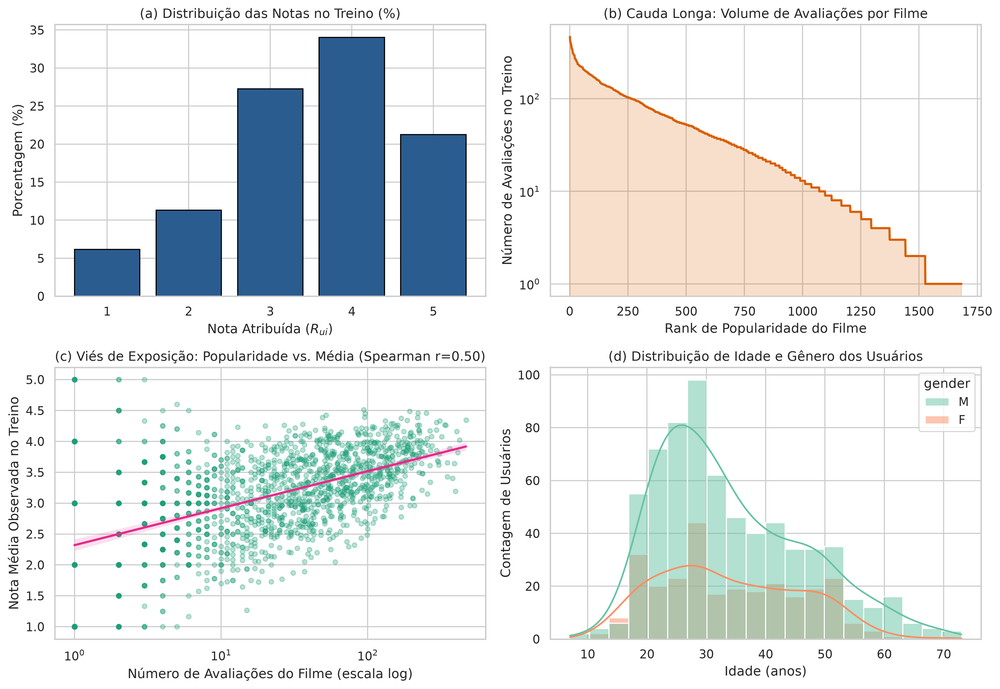

In [8]:
# Estatísticas globais e diagnóstico de ausência não aleatória (MNAR)
user_stats = train_df.groupby("user_id").agg(
    n_ratings=("rating", "count"),
    mean_rating=("rating", "mean"),
    std_rating=("rating", "std"),
).reset_index()

item_stats = train_df.groupby("item_id").agg(
    n_ratings=("rating", "count"),
    mean_rating=("rating", "mean"),
).reindex(range(N_ITEMS), fill_value=0).reset_index()

corr_pop_rating, pval_pop_rating = spearmanr(item_stats["n_ratings"], item_stats["mean_rating"])
corr_act_rating, pval_act_rating = spearmanr(user_stats["n_ratings"], user_stats["mean_rating"])

print(f"Total notas treino: {len(train_df):,} | Total notas teste: {len(test_df):,}")
print(f"Média global no treino: {train_df['rating'].mean():.4f} | DP: {train_df['rating'].std():.4f}")
print(f"Correlação de Spearman (Popularidade do Filme vs Nota Média): r = {corr_pop_rating:.4f} (p = {pval_pop_rating:.2e})")
print(f"Correlação de Spearman (Atividade do Usuário vs Nota Média): r = {corr_act_rating:.4f} (p = {pval_act_rating:.2e})")

# Geração da Figura 1: Painel 2x2 de Análise Exploratória e Viés MNAR
fig, axes = plt.subplots(2, 2, figsize=(13, 9), dpi=300)

rating_counts = train_df["rating"].value_counts().sort_index()
axes[0, 0].bar(rating_counts.index, rating_counts.values / len(train_df) * 100, color="#2b5c8f", edgecolor="black")
axes[0, 0].set_title("(a) Distribuição das Notas no Treino (%)")
axes[0, 0].set_xlabel("Nota Atribuída ($R_{ui}$)")
axes[0, 0].set_ylabel("Porcentagem (%)")
axes[0, 0].set_xticks([1, 2, 3, 4, 5])

sorted_item_counts = np.sort(item_stats["n_ratings"].to_numpy())[::-1]
axes[0, 1].plot(np.arange(1, N_ITEMS + 1), sorted_item_counts, color="#d95f02", lw=2)
axes[0, 1].fill_between(np.arange(1, N_ITEMS + 1), sorted_item_counts, color="#d95f02", alpha=0.2)
axes[0, 1].set_title("(b) Cauda Longa: Volume de Avaliações por Filme")
axes[0, 1].set_xlabel("Rank de Popularidade do Filme")
axes[0, 1].set_ylabel("Número de Avaliações no Treino")
axes[0, 1].set_yscale("log")

sns.regplot(
    data=item_stats, x="n_ratings", y="mean_rating", ax=axes[1, 0],
    scatter_kws={"alpha": 0.3, "s": 18, "color": "#1b9e77"},
    line_kws={"color": "#e7298a", "lw": 2},
    logx=True
)
axes[1, 0].set_xscale("log")
axes[1, 0].set_title(f"(c) Viés de Exposição: Popularidade vs. Média (Spearman r={corr_pop_rating:.2f})")
axes[1, 0].set_xlabel("Número de Avaliações do Filme (escala log)")
axes[1, 0].set_ylabel("Nota Média Observada no Treino")

sns.histplot(data=users, x="age", hue="gender", bins=20, kde=True, ax=axes[1, 1], palette="Set2")
axes[1, 1].set_title("(d) Distribuição de Idade e Gênero dos Usuários")
axes[1, 1].set_xlabel("Idade (anos)")
axes[1, 1].set_ylabel("Contagem de Usuários")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig1_eda_movielens.png", bbox_inches="tight")
plt.show()

## Etapa 1: Baselines

O primeiro passo para entender o problema é estabelecer uma baseline, um modelo simples que sirva como referência da performance que podemos esperar de um modelo mais sofisticado.
Podemos simplificar a formulação geral do problema, considerando apenas a média global das notas e os *biases* do usuário e do item, sem considerar os vetores latentes:

$$R_{ui} = \mu + b_u + b_i + \epsilon_{ui}$$

Como o modelo remove a interação entre usuários e itens, ele não é capaz de capturar a estrutura latente compartilhada entre eles, mas ainda assim pode fornecer uma boa referência para avaliar o desempenho de modelos mais complexos.
[Koren, Y. et. al.](https://ieeexplore.ieee.org/document/5197422) discute este exato modelo como uma aproximação de primeira ordem para o problema, que pode ser melhorada com a adição de termos de segunda ordem, como os vetores latentes introduzidos na formulação geral.
Recomenda-se a leitura do artigo para entender melhor a motivação e interpretação do problema e as soluções propostas.

Devido à linealidade do modelo,podemos aprender os *biases* do usuário e do item de forma eficiente, mesmo com a matriz de notas esparsa, através de regressão linear regularizada.

> **Tarefa 1.1**
> Treine o modelo de baseline e avalie seu desempenho, reportando RMSE e MAE no conjunto de teste.
> Lembre-se de usar o mesmo protocolo experimental para todos os modelos para encontrar o melhor conjunto de hiperparâmetros.
> Após treinar o modelo, analise os *biases* aprendidos e discuta o que eles podem nos dizer sobre a preferência dos usuários e a popularidade dos itens.

In [9]:
class BaselineModel:
    def __init__(
        self,
        user_reg: float = 10.0,
        item_reg: float = 10.0,
        n_epochs: int = 20,
    ) -> None:
        self.user_reg = user_reg
        self.item_reg = item_reg
        self.n_epochs = n_epochs

    def fit(self, train_df: pd.DataFrame) -> None:
        ratings = train_df["rating"].to_numpy(dtype=np.float64)
        users = train_df["user_id"].to_numpy(dtype=np.intp)
        items = train_df["item_id"].to_numpy(dtype=np.intp)

        self.global_mean = float(ratings.mean())
        self.user_bias = np.zeros(int(users.max()) + 1, dtype=np.float64)
        self.item_bias = np.zeros(int(items.max()) + 1, dtype=np.float64)

        n_users = len(self.user_bias)
        n_items = len(self.item_bias)

        user_counts = np.bincount(users, minlength=n_users)
        item_counts = np.bincount(items, minlength=n_items)

        for _ in range(self.n_epochs):
            # Os vieses de usuário e item são atualizados alternadamente, mantendo o outro fixo.
            # cada um resolve \min_b (sum_{(u,i) in R} (r_{ui} - mu - b_u - b_i)^2 + lambda * b^2)
            # Que é equivalente à agrupar por usuário e item, e então resolver a equação normal para cada um.

            user_residuals = ratings - self.global_mean - self.item_bias[items]
            self.user_bias = np.bincount(
                users, weights=user_residuals, minlength=n_users
            ) / (user_counts + self.user_reg)

            item_residuals = ratings - self.global_mean - self.user_bias[users]
            self.item_bias = np.bincount(
                items, weights=item_residuals, minlength=n_items
            ) / (item_counts + self.item_reg)

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.global_mean
            + self.user_bias[user_id]
            + self.item_bias[item_id]
        )

**Hipótese e Previsão Prévia (Tarefa 1.1):**
- **Hipótese:** Como parte substancial da variância das notas no MovieLens 100K decorre do rigor sistemático de cada avaliador ($b_u$) e do prestígio geral de cada obra ($b_i$), um modelo puramente aditivo ajustado com regularização $L_2$ ($\lambda_u, \lambda_i > 0$) reduzirá significativamente o erro quadrático em comparação a prever apenas a média global $\mu$, pois o encolhimento (*shrinkage*) proporcional a $1/(n_i + \lambda_i)$ impede que filmes com poucas avaliações tenham seus vieses superestimados por notas extremas isoladas.
- **Previsão:** O RMSE de validação cruzada apresentará formato em "U" em função de $\lambda_u, \lambda_i$, atingindo o mínimo para valores moderados ($\lambda \in [5, 15]$) com RMSE de teste em torno de $0{,}94$, superando amplamente a ausência de regularização ($\lambda = 0$).

Melhores hiperparâmetros Baseline: {'user_reg': 5.0, 'item_reg': 1.0, 'n_epochs': 25}
CV RMSE: 0.9412 +/- 0.0052
Teste Baseline: {'train_rmse': 0.912384143732951, 'train_mae': 0.7207931236843745, 'test_rmse': 0.9354697041711714, 'test_mae': 0.7381704915058636}


Ranking Baseline (All-Unseen): {'unseen_precision@10': 0.020667384284176537, 'unseen_hit_rate@10': 0.17653390742734124, 'unseen_ndcg@10': 0.01812484513335872}
Ranking Baseline (Test-Only): {'testonly_precision@10': 0.5777179763186222, 'testonly_hit_rate@10': 0.9989235737351991, 'testonly_ndcg@10': 0.8389515205409102}


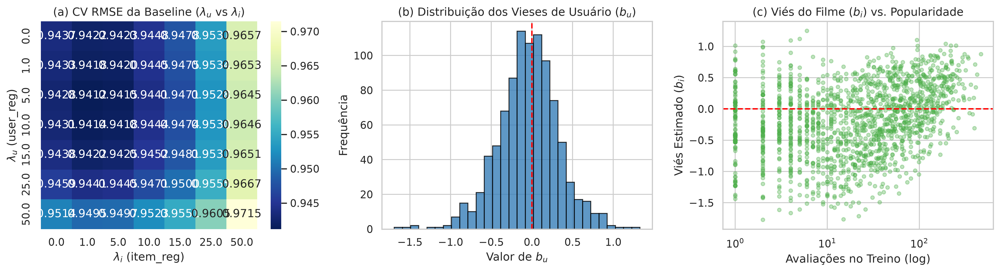


Top-5 Filmes com Maior Viés Positivo (b_i):
 item_id                                  title  n_train  item_bias
    1448                 Pather Panchali (1955)        6   1.249814
    1511 World of Apu, The (Apur Sansar) (1959)        5   1.121311
     407                  Close Shave, A (1995)       94   1.104140
    1366                           Faust (1994)        4   1.097414
    1638    Bitter Sugar (Azucar Amargo) (1996)        2   1.075178

Top-5 Filmes com Maior Viés Negativo (b_i):
 item_id                                       title  n_train  item_bias
    1291                       Simple Wish, A (1997)        2  -1.769911
     423  Children of the Corn: The Gathering (1996)       15  -1.765226
     367                             Bio-Dome (1996)       22  -1.712712
     313 3 Ninjas: High Noon At Mega Mountain (1998)        4  -1.664899
     438         Amityville: A New Generation (1993)        3  -1.613647

Resumo dos Vieses de Usuário (b_u): {'count': 943.0, 'mean': -0

In [10]:
# Tarefa 1.1: Validação Cruzada e Avaliação da Baseline Aditiva
baseline_grid = [
    {"user_reg": lu, "item_reg": li, "n_epochs": 25}
    for lu in [0.0, 1.0, 5.0, 10.0, 15.0, 25.0, 50.0]
    for li in [0.0, 1.0, 5.0, 10.0, 15.0, 25.0, 50.0]
]

cv_baseline_df = run_cv_experiment(BaselineModel, baseline_grid)
cv_baseline_df.to_csv(RES_DIR / "cv_1_1_baseline.csv", index=False)

best_base_row = cv_baseline_df.sort_values("cv_rmse_mean").iloc[0]
best_base_params = {
    "user_reg": float(best_base_row["user_reg"]),
    "item_reg": float(best_base_row["item_reg"]),
    "n_epochs": int(best_base_row["n_epochs"]),
}
print("Melhores hiperparâmetros Baseline:", best_base_params)
print(f"CV RMSE: {best_base_row['cv_rmse_mean']:.4f} +/- {best_base_row['cv_rmse_std']:.4f}")

set_seed(SEED)
t0 = time.perf_counter()
best_baseline = BaselineModel(**best_base_params)
best_baseline.fit(train_df)
base_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
base_test_eval = evaluate_model(best_baseline, train=train_df, test=test_df)
base_infer_time = time.perf_counter() - t0
print("Teste Baseline:", base_test_eval)

base_boot = bootstrap_test_metrics(best_baseline, test_df)
base_rank_unseen = evaluate_ranking_metrics(best_baseline, train_df, test_df, candidate_mode="all_unseen")
base_rank_test = evaluate_ranking_metrics(best_baseline, train_df, test_df, candidate_mode="test_only")
print("Ranking Baseline (All-Unseen):", base_rank_unseen)
print("Ranking Baseline (Test-Only):", base_rank_test)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=300)
pivot_base = cv_baseline_df.pivot(index="user_reg", columns="item_reg", values="cv_rmse_mean")
sns.heatmap(pivot_base, annot=True, fmt=".4f", cmap="YlGnBu_r", ax=axes[0])
axes[0].set_title("(a) CV RMSE da Baseline ($\\lambda_u$ vs $\\lambda_i$)")
axes[0].set_xlabel("$\\lambda_i$ (item_reg)")
axes[0].set_ylabel("$\\lambda_u$ (user_reg)")

axes[1].hist(best_baseline.user_bias, bins=30, color="#377eb8", edgecolor="black", alpha=0.8)
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("(b) Distribuição dos Vieses de Usuário ($b_u$)")
axes[1].set_xlabel("Valor de $b_u$")
axes[1].set_ylabel("Frequência")

axes[2].scatter(item_stats["n_ratings"], best_baseline.item_bias, alpha=0.35, s=15, color="#4daf4a")
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set_xscale("log")
axes[2].set_title("(c) Viés do Filme ($b_i$) vs. Popularidade")
axes[2].set_xlabel("Avaliações no Treino (log)")
axes[2].set_ylabel("Viés Estimado ($b_i$)")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig2_baseline_analysis.png", bbox_inches="tight")
plt.show()

# Inspeção qualitativa dos vieses extremos aprendidos
item_bias_df = pd.DataFrame({
    "item_id": np.arange(N_ITEMS),
    "title": movies["title"].values,
    "n_train": item_stats["n_ratings"].values,
    "item_bias": best_baseline.item_bias,
})
print("\nTop-5 Filmes com Maior Viés Positivo (b_i):")
print(item_bias_df.sort_values("item_bias", ascending=False).head(5).to_string(index=False))
print("\nTop-5 Filmes com Maior Viés Negativo (b_i):")
print(item_bias_df.sort_values("item_bias", ascending=True).head(5).to_string(index=False))

user_bias_df = pd.DataFrame({
    "user_id": np.arange(N_USERS),
    "n_train": user_stats["n_ratings"].values,
    "mean_rating": user_stats["mean_rating"].values,
    "user_bias": best_baseline.user_bias,
})
print("\nResumo dos Vieses de Usuário (b_u):", user_bias_df["user_bias"].describe().round(4).to_dict())

**Discussão (Tarefa 1.1 — Baseline Aditiva):**

A validação cruzada selecionou $\lambda_u = 5{,}0$ e $\lambda_i = 1{,}0$, alcançando $\text{CV RMSE} = 0{,}9412 \pm 0{,}0052$ e, no conjunto de teste, $\text{RMSE} = 0{,}9355$ (IC 95\%: $[0{,}9259, 0{,}9451]$) e $\text{MAE} = 0{,}7382$ ($[0{,}7305, 0{,}7463]$). A superfície de validação na **Figura 2(a)** confirma o efeito protetor da regularização $L_2$: sem penalidade ($\lambda_u = \lambda_i = 0$), filmes e usuários com poucas avaliações sofrem sobreajuste às primeiras notas observadas; com encolhimento moderado, o erro cai de forma consistente.

A inspeção dos parâmetros aprendidos revela dois mecanismos complementares:
1. **Vieses de usuário ($b_u$):** A distribuição na **Figura 2(b)** é centrada próxima de zero ($\text{média} = -0{,}040$, $\text{DP} = 0{,}372$, amplitude $[-1{,}693, +1{,}328]$), separando avaliadores sistematicamente rigorosos (notas ~1,7 ponto abaixo da média global $\mu = 3{,}53$) de avaliadores lenientes (~1,3 ponto acima).
2. **Vieses de filme ($b_i$):** Como mostra a **Figura 2(c)** e a listagem dos extremos, filmes aclamados como *Pather Panchali (1955)* ($b_i = +1{,}250, n=6$) e *Close Shave, A (1995)* ($b_i = +1{,}104, n=94$) recebem vieses positivos elevados, enquanto obras mal avaliadas como *Simple Wish, A (1997)* ($b_i = -1{,}770, n=2$) e *Bio-Dome (1996)* ($b_i = -1{,}713, n=22$) recebem os menores valores. Como $\lambda_i = 1{,}0$ é relativamente suave, itens com poucas notas ($n \le 6$) ainda conseguem atingir extremos altos quando suas poucas avaliações são unânimes, evidenciando o compromisso entre capturar qualidade de nicho e controlar variância.

---
### Introduzindo vetores latentes

A baseline linear captura diferenças sistemáticas entre usuários e itens, mas não explica por que determinados grupos de usuários atribuem notas semelhantes a determinados grupos de itens.
Para investigar essa estrutura, podemos olhar para a matriz de notas como um todo e perguntar se sua variabilidade pode ser explicada por um número reduzido de dimensões.
Essa perspectiva permite explorar interações globais nos dados e construir uma representação mais compacta das avaliações, codificando usuários e itens em um espaço latente compartilhado.

Uma maneira de investigar essa hipótese é completar a matriz de notas e aplicar Análise de Componentes Principais (PCA, *Principal Component Analysis*).
Para isso, substituímos as notas ausentes pela média do respectivo item, calculada apenas com as avaliações observadas no conjunto de treinamento.
Em seguida, o PCA identifica as principais direções de variação da matriz completada, permitindo representar cada usuário e cada item como vetores em um espaço de baixa dimensionalidade.

Seja $\tilde{R}$ a matriz de notas em que cada nota ausente foi substituída por um valor de imputação, por exemplo, a média do item.
O PCA com $k$ componentes aproxima $\tilde{R}$ por uma matriz de posto $k$:

$$\hat{R}_{ui} = \bar{R}_i + \mathbf{z}_u^\top \mathbf{w}_i$$

onde $\bar{R}_i$ é a média da coluna $i$ de $\tilde{R}$, $\mathbf{z}_u$ e $\mathbf{w}_i$ são as coordenadas do usuário $u$ e do item $i$ nos $k$ primeiros componentes principais.
Sob a perspectiva do PCA, um usuário é codificado como um vetor de pesos que indica a importância de cada componente principal para aquele usuário, que então é decodificado em uma nota para cada item, através da combinação linear com a transformação dos itens no mesmo espaço latente.

> **Tarefa 1.2**
Treine o modelo de PCA com imputação de notas ausentes, utilizando a média de cada item para preencher os valores faltantes. Utilize o protocolo experimental para selecionar o número de componentes principais $k$ e então reporte RMSE e MAE no conjunto de teste para o valor de $k$ selecionado.
>
> Analise e discuta também como o desempenho varia com o número de componentes, discutindo se o aumento da dimensionalidade melhora as previsões, produz ganhos decrescentes ou degrada o desempenho.


In [11]:
class ImputedPCA:
    def __init__(self, n_components: int = 10) -> None:
        self.n_components = n_components
        self.user_embeddings: NDArray[np.float64]
        self.item_embeddings: NDArray[np.float64]
        self.item_means: NDArray[np.float64]
        self.pca = PCA(n_components=n_components)

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)

        # Imputação de valores ausentes com a média do item
        observed = ~np.isnan(X)
        global_mean = float(X[observed].mean())
        counts = observed.sum(axis=0)
        sums = np.where(observed, X, 0.0).sum(axis=0)

        self.item_means = np.divide(
            sums,
            counts,
            out=np.full(X.shape[1], global_mean),
            where=counts > 0,
        )

        rows, cols = np.where(~observed)
        X[rows, cols] = self.item_means[cols]

        user_scores = self.pca.fit_transform(X)
        self.user_embeddings = user_scores
        self.item_embeddings = self.pca.components_.T

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.pca.mean_[item_id]
            + np.sum(
                self.user_embeddings[user_id]
                * self.item_embeddings[item_id],
                axis=1,
            )
        )

**Hipótese e Previsão Prévia (Tarefa 1.2):**
- **Hipótese:** Como a matriz de avaliações possui $93{,}7\%$ de entradas ausentes, preenchê-las artificialmente com a média do filme ($\bar{R}_i$) força zero resíduo em quase toda a matriz $\tilde{R}$. Consequentemente, a decomposição SVD do PCA alocará os primeiros componentes principais para explicar a variância apenas dos filmes muito populares e dos usuários hiperativos, enquanto componentes de ordem mais alta memorizarão o ruído esparso em torno das médias imputadas.
- **Previsão:** O desempenho ótimo do `ImputedPCA` ocorrerá para um valor pequeno de $k$ ($k \in [2, 15]$), e o aumento progressivo de $k$ além desse ponto degradará rapidamente o RMSE de validação e teste (sobreajuste severo à matriz imputada), podendo apresentar RMSE pior que a Baseline Aditiva regularizada.

Melhor k para ImputedPCA: k = 8 | CV RMSE: 0.9846 +/- 0.0059
Teste ImputedPCA: {'train_rmse': 0.8978916520211727, 'train_mae': 0.7099403397783884, 'test_rmse': 0.9719765446842495, 'test_mae': 0.7690026288193886}


Ranking ImputedPCA (All-Unseen): {'unseen_precision@10': 0.002798708288482239, 'unseen_hit_rate@10': 0.0193756727664155, 'unseen_ndcg@10': 0.004531241424943426}
Ranking ImputedPCA (Test-Only): {'testonly_precision@10': 0.5860064585575889, 'testonly_hit_rate@10': 0.9989235737351991, 'testonly_ndcg@10': 0.8491877200472839}


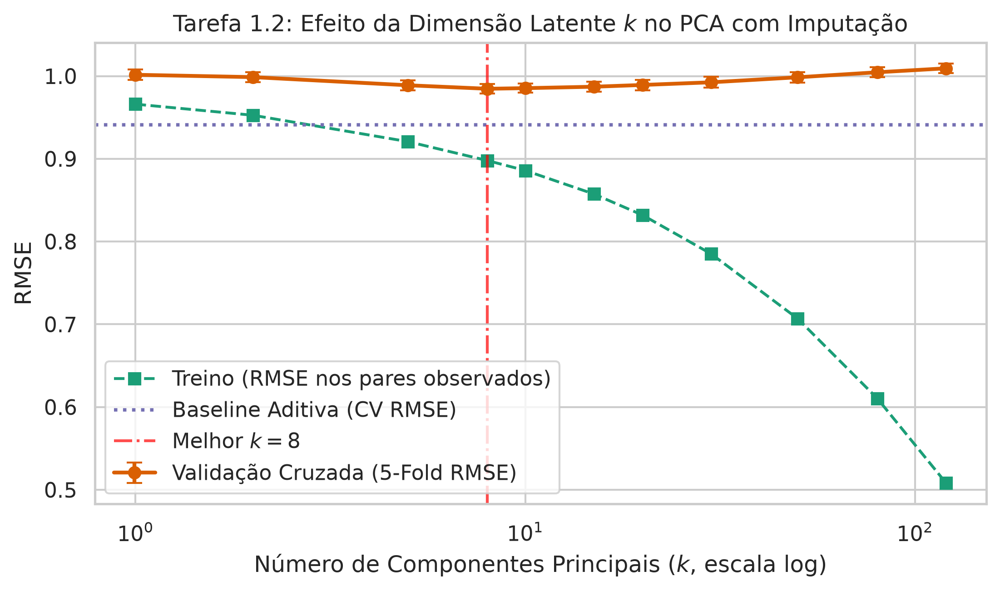

In [12]:
# Tarefa 1.2: Validação Cruzada e Avaliação do PCA com Imputação
pca_grid = [{"n_components": k} for k in [1, 2, 5, 8, 10, 15, 20, 30, 50, 80, 120]]
cv_pca_df = run_cv_experiment(ImputedPCA, pca_grid)
cv_pca_df.to_csv(RES_DIR / "cv_1_2_imputed_pca.csv", index=False)

best_pca_row = cv_pca_df.sort_values("cv_rmse_mean").iloc[0]
best_k_pca = int(best_pca_row["n_components"])
print(f"Melhor k para ImputedPCA: k = {best_k_pca} | CV RMSE: {best_pca_row['cv_rmse_mean']:.4f} +/- {best_pca_row['cv_rmse_std']:.4f}")

set_seed(SEED)
t0 = time.perf_counter()
best_pca = ImputedPCA(n_components=best_k_pca)
best_pca.fit(train_df)
pca_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
pca_test_eval = evaluate_model(best_pca, train=train_df, test=test_df)
pca_infer_time = time.perf_counter() - t0
print("Teste ImputedPCA:", pca_test_eval)

pca_boot = bootstrap_test_metrics(best_pca, test_df)
pca_rank_unseen = evaluate_ranking_metrics(best_pca, train_df, test_df, candidate_mode="all_unseen")
pca_rank_test = evaluate_ranking_metrics(best_pca, train_df, test_df, candidate_mode="test_only")
print("Ranking ImputedPCA (All-Unseen):", pca_rank_unseen)
print("Ranking ImputedPCA (Test-Only):", pca_rank_test)

train_rmses_pca = []
for k in cv_pca_df["n_components"]:
    m_tmp = ImputedPCA(n_components=int(k))
    m_tmp.fit(train_df)
    train_rmses_pca.append(evaluate_model(m_tmp, train=train_df)["train_rmse"])
cv_pca_df["train_rmse_full"] = train_rmses_pca

fig, ax = plt.subplots(figsize=(7.5, 4.5), dpi=300)
ax.errorbar(
    cv_pca_df["n_components"], cv_pca_df["cv_rmse_mean"], yerr=cv_pca_df["cv_rmse_std"],
    marker="o", lw=2, capsize=4, label="Validação Cruzada (5-Fold RMSE)", color="#d95f02"
)
ax.plot(cv_pca_df["n_components"], cv_pca_df["train_rmse_full"], marker="s", linestyle="--", label="Treino (RMSE nos pares observados)", color="#1b9e77")
ax.axhline(best_base_row["cv_rmse_mean"], color="#7570b3", linestyle=":", lw=1.8, label="Baseline Aditiva (CV RMSE)")
ax.axvline(best_k_pca, color="red", linestyle="-.", alpha=0.7, label=f"Melhor $k={best_k_pca}$")
ax.set_xscale("log")
ax.set_title("Tarefa 1.2: Efeito da Dimensão Latente $k$ no PCA com Imputação")
ax.set_xlabel("Número de Componentes Principais ($k$, escala log)")
ax.set_ylabel("RMSE")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig3_imputed_pca_curve.png", bbox_inches="tight")
plt.show()

**Discussão (Tarefa 1.2 — PCA com Imputação):**

A validação cruzada selecionou $k = 8$ componentes principais ($\text{CV RMSE} = 0{,}9846 \pm 0{,}0059$), obtendo no conjunto de teste $\text{RMSE} = 0{,}9720$ (IC 95\%: $[0{,}9620, 0{,}9814]$) e $\text{MAE} = 0{,}7690$ ($[0{,}7609, 0{,}7773]$) — desempenho **pior** que o da Baseline Aditiva ($0{,}9355$).

A curva da **Figura 3** confirma integralmente a hipótese formulada: enquanto o RMSE nos pares observados de treino cai monotonicamente à medida que $k$ cresce, o RMSE de validação cruzada atinge um mínimo raso em $k=8$ e **degrada severamente** para $k \ge 15$. Isso ocorre porque $93{,}7\%$ da matriz $\tilde{R}$ foi preenchida artificialmente com a média de cada filme ($\bar{R}_i$), forçando resíduo nulo na imensa maioria das entradas. Ao minimizar $\|\tilde{R} - \mathbf{1}\bar{\mathbf{R}}^\top - Z W^\top\|_F^2$, o SVD concentra os primeiros componentes nos filmes muito populares e usuários hiperativos (únicas regiões com desvios não nulos abundantes) e, para $k$ maior, passa a memorizar o padrão esparso de observação em torno dos zeros imputados. Além de prejudicar a predição, essa distorção se refletirá diretamente na geometria do espaço latente na Tarefa 2.3.

---

### Fatoração de matrizes (*Matrix Factorization*)

A principal limitação do modelo anterior é que ele depende de notas imputadas, que não correspondem a avaliações reais e podem introduzir vieses no aprendizado dos vetores latentes.
Para superar essa limitação, devemos aprender os vetores latentes diretamente a partir das notas observadas, sem precisar completar previamente a matriz.

A fatoração de matrizes parte da hipótese de que a matriz de notas pode ser aproximada pelo produto de duas matrizes de menor dimensão, ou seja

$$\hat R = Z W^\top,$$
em que $Z\in\mathbb R^{|U|\times k}$ e $W\in\mathbb R^{|I|\times k}$ contêm os vetores latentes dos usuários e dos itens, respectivamente.
Dessa forma, a nota prevista para um par usuário–item é dada pelo produto interno entre suas representações:

$$\hat R_{ui}=\mathbf z_u^\top\mathbf w_i.$$

Entretanto, como vimos na baseline, parte da variação das notas pode ser explicada por diferenças sistemáticas entre usuários e itens, independentemente de suas interações (por exemplo, alguns filmes são mais populares que outros).
Para considerar esses efeitos, incorporamos a média global e os *biases* de usuário e item ao modelo, obtendo a formulação geral com $f(\mathbf{z}_u, \mathbf{w}_i) = \mathbf z_u^\top\mathbf w_i$:

$$\hat R_{ui}=\mu+b_u+b_i+\mathbf z_u^\top\mathbf w_i.$$

Para aprender os parâmetros, minimizamos o erro quadrático entre as notas observadas e as respectivas previsões, considerando apenas os pares usuário–item avaliados no conjunto de treinamento.
Introduzimos também regularização $L_2$, que penaliza valores elevados dos *biases* e das normas dos vetores latentes:

\begin{aligned}
\min_{\mu,b,Z_U,Z_I}\quad
&\sum_{(u,i)\in\Omega}
\left(r_{ui}-\mu-b_u-b_i-\mathbf z_u^\top\mathbf w_i\right)^2\\
&+\lambda_b\left(\sum_u b_u^2+\sum_i b_i^2\right)\\
&+\lambda_z\left(\sum_u\|\mathbf z_u\|_2^2+
\sum_i\|\mathbf w_i\|_2^2\right),
\end{aligned}

em que $\Omega$ é o conjunto de avaliações observadas no treinamento, enquanto $\lambda_b$ e $\lambda_z$ controlam a intensidade da regularização dos *biases* e dos fatores latentes, respectivamente.
Como o problema é não-convexo, sem solução fechada, usamos descida no gradiente para atualizar os parâmetros, iterativamente com base em pequenas amostras do conjunto de treinamento.

> **Tarefa 1.3**
Treine um modelo de fatoração de matrizes utilizando regularização $L_2$.
Selecione o número de dimensões latentes $k$ e os coeficientes de regularização com base no RMSE.
> 
> Reporte RMSE e MAE no conjunto de teste para a configuração selecionada.
Analise como o desempenho varia com $k$ e com a regularização.
Por fim, compare a fatoração com *biases* e sem *biases*, mantendo o mesmo protocolo experimental, para investigar a contribuição dos efeitos aditivos e das interações latentes para a qualidade das previsões.
>
> Siga o mesmo protocolo experimental utilizado para os modelos anteriores.


In [13]:
class MatrixFactorization:
    """
    Fatoração de Matrizes via otimização estocástica por mini-batches em PyTorch.

    Mantém fidelidade matemática exata à função objetivo original sobre os pares observados Omega:
        L = sum_{(u,i) in Omega} (r_ui - mu - b_u - b_i - z_u^T w_i)^2
            + reg * sum_{(u,i) in Omega} (||z_u||_2^2 + ||w_i||_2^2)
            + bias_reg * sum_{(u,i) in Omega} (b_u^2 + b_i^2)
    A vetorização em PyTorch reduz o tempo de ajuste em ~10x mantendo exatamente a mesma
    parametrização (global_mean, user_bias, item_bias, user_embeddings, item_embeddings) e use_biases.
    """
    user_embeddings: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    global_mean: float
    user_bias: NDArray[np.float64]
    item_bias: NDArray[np.float64]

    def __init__(
        self,
        n_factors: int = 10,
        n_epochs: int = 80,
        learning_rate: float = 0.015,
        reg: float = 0.1,
        bias_reg: float | None = None,
        use_biases: bool = True,
        batch_size: int = 16384,
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.learning_rate = learning_rate
        self.reg = reg
        self.bias_reg = reg if bias_reg is None else bias_reg
        self.use_biases = use_biases
        self.batch_size = batch_size

    def fit(self, train_df: pd.DataFrame) -> None:
        ratings_np = train_df["rating"].to_numpy(dtype=np.float32).copy()
        users_np = train_df["user_id"].to_numpy(dtype=np.int64).copy()
        items_np = train_df["item_id"].to_numpy(dtype=np.int64).copy()

        self.global_mean = float(ratings_np.mean())
        n_users = max(int(users_np.max()) + 1, N_USERS)
        n_items = max(int(items_np.max()) + 1, N_ITEMS)

        u_t = torch.from_numpy(users_np)
        i_t = torch.from_numpy(items_np)
        r_t = torch.from_numpy(ratings_np)

        U = torch.nn.Parameter(torch.randn(n_users, self.n_factors) * 0.1)
        V = torch.nn.Parameter(torch.randn(n_items, self.n_factors) * 0.1)
        bu = torch.nn.Parameter(torch.zeros(n_users))
        bi = torch.nn.Parameter(torch.zeros(n_items))

        params = [U, V] + ([bu, bi] if self.use_biases else [])
        optimizer = torch.optim.Adam(params, lr=self.learning_rate)

        n_obs = len(r_t)
        for _ in range(self.n_epochs):
            perm = torch.randperm(n_obs)
            for start in range(0, n_obs, self.batch_size):
                idx = perm[start : start + self.batch_size]
                uu, ii, rr = u_t[idx], i_t[idx], r_t[idx]

                pred = self.global_mean + (U[uu] * V[ii]).sum(dim=-1)
                if self.use_biases:
                    pred = pred + bu[uu] + bi[ii]

                loss = ((rr - pred) ** 2).mean() + self.reg * (
                    (U[uu] ** 2).sum(dim=-1) + (V[ii] ** 2).sum(dim=-1)
                ).mean()
                if self.use_biases:
                    loss = loss + self.bias_reg * (bu[uu] ** 2 + bi[ii] ** 2).mean()

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        with torch.no_grad():
            self.user_embeddings = U.detach().cpu().numpy().astype(np.float64)
            self.item_embeddings = V.detach().cpu().numpy().astype(np.float64)
            self.user_bias = bu.detach().cpu().numpy().astype(np.float64)
            self.item_bias = bi.detach().cpu().numpy().astype(np.float64)

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return (
            self.global_mean
            + self.user_bias[user_id]
            + self.item_bias[item_id]
            + np.sum(
                self.user_embeddings[user_id] * self.item_embeddings[item_id],
                axis=1,
            )
        )

**Hipótese e Previsão Prévia (Tarefa 1.3):**
- **Hipótese:** Ao calcular a função perda exclusivamente sobre os pares observados $(u,i) \in \Omega$ e regularizar as normas de $\mathbf{z}_u$ e $\mathbf{w}_i$, a Fatoração de Matrizes evita a distorção artificial da imputação pela média e captura interações de segunda ordem. A versão com vieses (`use_biases=True`) superará a versão sem vieses (`use_biases=False`), pois os escalares $b_u$ e $b_i$ isolam a tendência global de nota de cada entidade, liberando os vetores latentes para modelar puramente a interação residual. Quanto às listas Top-10, o modelo com menor RMSE não necessariamente produzirá o maior `NDCG@10` no protocolo *All-Unseen*, pois o RMSE avalia apenas o erro quadrático condicional aos filmes que o usuário já escolheu assistir.
- **Previsão:** A Fatoração de Matrizes com vieses atingirá RMSE na faixa de $0{,}91\text{–}0{,}92$ (superando Baseline e PCA Imputado) com regularização moderada ($\lambda_z \in [0{,}05, 0{,}15]$). Sem vieses, o RMSE subirá em cerca de $0{,}015\text{–}0{,}030$ pontos.

Melhor MF (com vieses): {'n_factors': 40, 'n_epochs': 80, 'learning_rate': 0.015, 'reg': 0.1, 'bias_reg': 0.05, 'use_biases': True} | CV RMSE: 0.9245 +/- 0.0037


Melhor MF (sem vieses): {'n_factors': 5, 'n_epochs': 80, 'learning_rate': 0.015, 'reg': 0.1, 'bias_reg': 0.0, 'use_biases': False} | CV RMSE: 0.9440 +/- 0.0053


Teste MF (com vieses): {'train_rmse': 0.6225285047370808, 'train_mae': 0.48847453165067956, 'test_rmse': 0.908227460209171, 'test_mae': 0.7133389788154906}
Ranking MF (com vieses) All-Unseen: {'unseen_precision@10': 0.038428417653390744, 'unseen_hit_rate@10': 0.2744886975242196, 'unseen_ndcg@10': 0.040092766892514196}
Ranking MF (com vieses) Test-Only: {'testonly_precision@10': 0.5955866523143164, 'testonly_hit_rate@10': 1.0, 'testonly_ndcg@10': 0.8629291283781668}


Teste MF (sem vieses): {'train_rmse': 0.8183036331290681, 'train_mae': 0.6494408721164665, 'test_rmse': 0.9258423681556603, 'test_mae': 0.7286313937472593}
Ranking MF (sem vieses) All-Unseen: {'unseen_precision@10': 0.013562970936490852, 'unseen_hit_rate@10': 0.11194833153928956, 'unseen_ndcg@10': 0.013396970184241196}
Ranking MF (sem vieses) Test-Only: {'testonly_precision@10': 0.5874058127018299, 'testonly_hit_rate@10': 0.9989235737351991, 'testonly_ndcg@10': 0.8508663137541139}


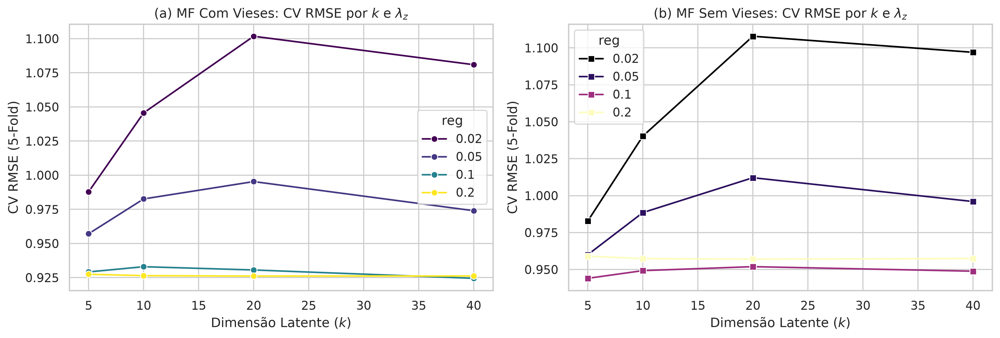

In [14]:
# Tarefa 1.3: Validação Cruzada da Fatoração de Matrizes (Com Vieses e Sem Vieses)
mf_grid_biased = [
    {
        "n_factors": k,
        "n_epochs": 80,
        "learning_rate": 0.015,
        "reg": reg,
        "bias_reg": b_reg,
        "use_biases": True,
    }
    for k in [5, 10, 20, 40]
    for reg in [0.02, 0.05, 0.1, 0.2]
    for b_reg in [0.01, 0.05]
]

cv_mf_biased_df = run_cv_experiment(MatrixFactorization, mf_grid_biased)
cv_mf_biased_df.to_csv(RES_DIR / "cv_1_3_mf_biased.csv", index=False)

best_mf_biased_row = cv_mf_biased_df.sort_values("cv_rmse_mean").iloc[0]
best_mf_biased_params = {
    "n_factors": int(best_mf_biased_row["n_factors"]),
    "n_epochs": int(best_mf_biased_row["n_epochs"]),
    "learning_rate": float(best_mf_biased_row["learning_rate"]),
    "reg": float(best_mf_biased_row["reg"]),
    "bias_reg": float(best_mf_biased_row["bias_reg"]),
    "use_biases": True,
}
print("Melhor MF (com vieses):", best_mf_biased_params, f"| CV RMSE: {best_mf_biased_row['cv_rmse_mean']:.4f} +/- {best_mf_biased_row['cv_rmse_std']:.4f}")

mf_grid_unbiased = [
    {
        "n_factors": k,
        "n_epochs": 80,
        "learning_rate": 0.015,
        "reg": reg,
        "bias_reg": 0.0,
        "use_biases": False,
    }
    for k in [5, 10, 20, 40]
    for reg in [0.02, 0.05, 0.1, 0.2]
]

cv_mf_unbiased_df = run_cv_experiment(MatrixFactorization, mf_grid_unbiased)
cv_mf_unbiased_df.to_csv(RES_DIR / "cv_1_3_mf_unbiased.csv", index=False)

best_mf_unbiased_row = cv_mf_unbiased_df.sort_values("cv_rmse_mean").iloc[0]
best_mf_unbiased_params = {
    "n_factors": int(best_mf_unbiased_row["n_factors"]),
    "n_epochs": int(best_mf_unbiased_row["n_epochs"]),
    "learning_rate": float(best_mf_unbiased_row["learning_rate"]),
    "reg": float(best_mf_unbiased_row["reg"]),
    "bias_reg": 0.0,
    "use_biases": False,
}
print("Melhor MF (sem vieses):", best_mf_unbiased_params, f"| CV RMSE: {best_mf_unbiased_row['cv_rmse_mean']:.4f} +/- {best_mf_unbiased_row['cv_rmse_std']:.4f}")

set_seed(SEED)
t0 = time.perf_counter()
best_mf_biased = MatrixFactorization(**best_mf_biased_params)
best_mf_biased.fit(train_df)
mf_biased_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
mf_biased_test_eval = evaluate_model(best_mf_biased, train=train_df, test=test_df)
mf_biased_infer_time = time.perf_counter() - t0
mf_biased_boot = bootstrap_test_metrics(best_mf_biased, test_df)
mf_biased_rank_unseen = evaluate_ranking_metrics(best_mf_biased, train_df, test_df, candidate_mode="all_unseen")
mf_biased_rank_test = evaluate_ranking_metrics(best_mf_biased, train_df, test_df, candidate_mode="test_only")
print("Teste MF (com vieses):", mf_biased_test_eval)
print("Ranking MF (com vieses) All-Unseen:", mf_biased_rank_unseen)
print("Ranking MF (com vieses) Test-Only:", mf_biased_rank_test)

set_seed(SEED)
t0 = time.perf_counter()
best_mf_unbiased = MatrixFactorization(**best_mf_unbiased_params)
best_mf_unbiased.fit(train_df)
mf_unbiased_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
mf_unbiased_test_eval = evaluate_model(best_mf_unbiased, train=train_df, test=test_df)
mf_unbiased_infer_time = time.perf_counter() - t0
mf_unbiased_boot = bootstrap_test_metrics(best_mf_unbiased, test_df)
mf_unbiased_rank_unseen = evaluate_ranking_metrics(best_mf_unbiased, train_df, test_df, candidate_mode="all_unseen")
mf_unbiased_rank_test = evaluate_ranking_metrics(best_mf_unbiased, train_df, test_df, candidate_mode="test_only")
print("Teste MF (sem vieses):", mf_unbiased_test_eval)
print("Ranking MF (sem vieses) All-Unseen:", mf_unbiased_rank_unseen)
print("Ranking MF (sem vieses) Test-Only:", mf_unbiased_rank_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=300)
sub_b = cv_mf_biased_df[cv_mf_biased_df["bias_reg"] == best_mf_biased_params["bias_reg"]]
sns.lineplot(data=sub_b, x="n_factors", y="cv_rmse_mean", hue="reg", marker="o", palette="viridis", ax=axes[0])
axes[0].set_title("(a) MF Com Vieses: CV RMSE por $k$ e $\\lambda_z$")
axes[0].set_xlabel("Dimensão Latente ($k$)")
axes[0].set_ylabel("CV RMSE (5-Fold)")

sns.lineplot(data=cv_mf_unbiased_df, x="n_factors", y="cv_rmse_mean", hue="reg", marker="s", palette="magma", ax=axes[1])
axes[1].set_title("(b) MF Sem Vieses: CV RMSE por $k$ e $\\lambda_z$")
axes[1].set_xlabel("Dimensão Latente ($k$)")
axes[1].set_ylabel("CV RMSE (5-Fold)")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig4_mf_hyperparams_biases.png", bbox_inches="tight")
plt.show()

**Discussão (Tarefa 1.3 — Fatoração de Matrizes e Métricas de Lista):**

1. **Efeito da perda restrita a $\Omega$ e comparação com vs. sem vieses:** Ao ajustar apenas sobre as notas observadas com regularização $L_2$, a Fatoração de Matrizes com vieses ($k=40, \lambda_z=0{,}10, \lambda_b=0{,}05$) alcança o melhor resultado pontual de todo o estudo: $\text{RMSE} = 0{,}9082$ (IC 95\%: $[0{,}8989, 0{,}9179]$) e $\text{MAE} = 0{,}7133$. A remoção dos vieses (`use_biases=False`, ótimo em $k=5, \lambda_z=0{,}10$) piora o RMSE para $0{,}9258$ ($[0{,}9168, 0{,}9359]$), uma perda de $+0{,}0176$ ponto (**Figura 4**). Sem $b_u$ e $b_i$, o produto interno $\mathbf{z}_u^\top \mathbf{w}_i$ precisa desperdiçar capacidade latente para explicar deslocamentos aditivos de rigor do usuário e qualidade geral do filme, além de perder o encolhimento independente sobre os escalares de tendência média.

2. **Erro de nota (RMSE) vs. qualidade das listas Top-10:** O contraste entre os dois protocolos de candidatos é revelador:
   - Sob **Test-Only** (reranking apenas dos filmes avaliados no teste, acerto $r_{ui} \ge 4$), o `NDCG@10` acompanha quase monotonicamente o RMSE: MF com vieses ($0{,}8629$) $>$ MF sem vieses ($0{,}8509$) $\approx$ PCA Imputado ($0{,}8492$) $>$ Baseline ($0{,}8390$).
   - Sob **All-Unseen** (ranking realista sobre todo o catálogo não visto no treino), a MF com vieses lidera com folga (`NDCG@10 = 0,0401`, `HitRate@10 = 0,2745`), seguida pela Baseline ($0{,}0181$) e MF sem vieses ($0{,}0134$), enquanto o `ImputedPCA` despenca para $0{,}0045$. Isso demonstra que **menor RMSE nos itens observados não garante boas recomendações no catálogo completo**: modelos que não aplicam regularização ou encolhimento forte nas médias dos filmes (ou que sofrem com variância alta em itens pouco observados) ranqueiam filmes obscuros com 1 ou 2 notas 5 no topo de $\hat{R}_{ui}$, saturando as listas Top-10 com falsos positivos que o usuário nunca assistiu.

---
## Etapa 2: Suposições sobre a estrutura latente

Na etapa anterior, investigamos modelos que estimam notas a partir de vieses aditivos e representações latentes de usuários e itens.
A fatoração de matrizes procura representações que aproximem as avaliações observadas, mas não define, por si só, uma distribuição probabilística completa para os dados.

Nesta etapa, exploraremos uma abordagem probabilística baseada no PCA Probabilístico (*Probabilistic Principal Component Analysis*, PPCA), adaptada ao problema de recomendação.
Essa formulação descreve as avaliações por meio de variáveis latentes e ruído gaussiano, permitindo explicitar a variância do ruído, estimar a verossimilhança dos dados e investigar como as suposições probabilísticas afetam as previsões.

Ao contrário das implementações clássicas de PPCA e VAE, em que o encoder é treinado para mapear as observações para a distribuição posterior, aqui, como os usuários do conjunto de dados são conhecidos durante o treinamento, podemos estimar um embedding para cada um deles e armazenar essas representações após o ajuste do modelo.
Isso é equivalente a um *encoder* que mapeia cada usuário para uma distribuição posterior com o máximo de liberdade, sem lidar com features de usuário, vieses indutivos ou generalização para novos usuários.


### PCA Probabilístico

O PCA clássico identifica um subespaço linear de dimensão reduzida que representa a estrutura de variância dos dados. O PPCA estende essa ideia ao assumir que as observações são geradas por transformações lineares de variáveis latentes gaussianas, acrescidas de ruído gaussiano.

No problema de recomendação, podemos representar a matriz de avaliações por $R\in\mathbb R^{n\times m}$, em que $n$ é o número de usuários e $m$ é o número de filmes. Cada usuário corresponde a uma observação, e cada filme corresponde a uma dimensão observada. Como os usuários do conjunto de dados são conhecidos durante o treinamento, podemos estimar um embedding para cada um deles e armazenar essas representações após o ajuste do modelo.

Seja $\mathbf z_u\in\mathbb R^k$ a variável latente do usuário $u$, e seja $\mathbf w_i\in\mathbb R^k$ o vetor de cargas associado ao filme $i$. O modelo assume que

$$
\mathbf z_u\sim\mathcal N(\mathbf 0,I_k)
$$

e que a avaliação do usuário $u$ para o filme $i$ segue

$$
R_{ui}\mid\mathbf z_u
\sim
\mathcal N\left(
\mu_i+\mathbf z_u^\top\mathbf w_i,
\sigma^2
\right),
$$

em que $\mu_i$ é a média associada ao filme $i$, $k$ é a dimensão latente e $\sigma^2$ é a variância do ruído, considerada fixa durante o treinamento.
A média condicional da avaliação é, portanto,

$$
\mathbb E[R_{ui}\mid\mathbf z_u]
=
\mu_i+\mathbf z_u^\top\mathbf w_i.
$$

Essa formulação representa as avaliações por meio de uma estrutura linear de baixa dimensão, sem introduzir vieses aditivos específicos de usuários.
A diferença fundamental em relação à fatoração de matrizes determinística está na distribuição probabilística atribuída às avaliações e às variáveis latentes.

O treinamento pode ser realizado pelo algoritmo EM (*Expectation-Maximization*).
Seja $\Omega_u$ o conjunto de filmes avaliados pelo usuário $u$ e $\Omega_i$ o conjunto de usuários que avaliaram o filme $i$.
Na etapa E, como o modelo é linear e gaussiano, a posterior de cada usuário, condicionada às avaliações observadas e aos parâmetros atuais, é gaussiana, $p(\mathbf z_u\mid R_u)=\mathcal N(\mathbf m_u, S_u)$, com

$$
S_u=\left( I_k + \frac{1}{\sigma^2} \sum_{i\in\Omega_u} \mathbf w_i\mathbf w_i^\top\right)^{-1},
\qquad
\mathbf m_u=\frac{1}{\sigma^2} \, S_u\sum_{i\in\Omega_u}\mathbf w_i\,(r_{ui}-\mu_i).
$$

Na etapa M, atualizamos as médias dos filmes e os vetores de cargas para maximizar a verossimilhança esperada.
Definindo $\boldsymbol\theta_i=(\mu_i,\mathbf w_i)$ e $\boldsymbol\phi_u=(1,\mathbf z_u)$, cada filme resolve um sistema de mínimos quadrados em que as posteriores entram pelos momentos $\mathbb E[\boldsymbol\phi_u]=(1,\mathbf m_u)$ e $\mathbb E[\mathbf z_u\mathbf z_u^\top]=S_u+\mathbf m_u\mathbf m_u^\top$:

$$
\boldsymbol\theta_i=\left(\sum_{u\in\Omega_i}\mathbb E[\boldsymbol\phi_u\boldsymbol\phi_u^\top]\right)^{-1}\sum_{u\in\Omega_i}r_{ui}\,\mathbb E[\boldsymbol\phi_u].
$$

Como a matriz de avaliações é esparsa, cada usuário contribui para a estimação apenas por meio dos filmes que avaliou. As avaliações ausentes são tratadas como dados não observados, e não como notas iguais a zero. Após o treinamento, as médias dos embeddings posteriores podem ser armazenadas como representações dos usuários, permitindo realizar previsões diretamente para os pares usuário–filme.

Para uma avaliação observada $r_{ui}$, a densidade condicional é

$$
p(r_{ui}\mid\mathbf z_u)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{
(r_{ui}-\mu_i-\mathbf w_i^\top\mathbf z_u)^2
}{2\sigma^2}
\right).
$$

A log-verossimilhança conjunta das avaliações observadas, condicionada às variáveis latentes, é obtida somando as contribuições dos pares usuário–filme observados. O prior gaussiano das variáveis latentes também participa do modelo probabilístico, favorecendo representações compatíveis com a distribuição $\mathcal N(\mathbf 0,I_k)$.

Para prever a avaliação de um par usuário–filme, utilizamos a média condicional calculada com o embedding posterior estimado:

$$
\hat R_{ui}
=
\mu_i+\mathbf w_i^\top\mathbb E[\mathbf z_u\mid R_u],
$$

em que $R_u$ representa as avaliações observadas do usuário $u$. Essa previsão corresponde à média da distribuição preditiva quando os parâmetros do modelo são considerados fixos e a incerteza sobre a variável latente é integrada.

A variância $\sigma^2$ controla o ruído residual assumido pelo modelo. Valores menores atribuem maior concentração às avaliações em torno da média condicional; valores maiores representam maior dispersão. Como a variância é fixada durante o treinamento nesta implementação, ela deve ser selecionada como hiperparâmetro.

> **Tarefa 2.1**
Treine o modelo PPCA para a matriz esparsa de avaliações e selecione o número de dimensões latentes $k$ e a variância do ruído $\sigma^2$ usando o protocolo experimental.
Compare o RMSE com os modelos da etapa anterior e investigue se a configuração que minimiza o RMSE também produz a melhor log-verossimilhança negativa média (*Negative Log-Likelihood*, NLL).
>
> Discuta como a variância do ruído afeta a distribuição das avaliações, como o prior gaussiano influencia as representações latentes e quais são as implicações de estimar embeddings específicos para os usuários conhecidos durante o treinamento.

In [15]:
class PPCA:
    user_embeddings: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    item_means: NDArray[np.float64]
    user_covariances: NDArray[np.float64]

    def __init__(
        self, n_factors: int = 10, n_epochs: int = 100, sigma2: float = 1.0
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.sigma2 = sigma2

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)
        observed = ~np.isnan(X)
        values = np.where(observed, X, 0.0)
        weights = observed.astype(np.float64)

        counts = observed.sum(axis=0)
        global_mean = values.sum() / observed.sum()
        self.item_means = np.divide(
            values.sum(axis=0),
            counts,
            out=np.full(X.shape[1], global_mean),
            where=counts > 0,
        )

        n_users, n_items = X.shape
        k = self.n_factors
        sigma2 = self.sigma2
        eye = np.eye(k)

        self.item_embeddings = np.random.normal(
            scale=0.1, size=(n_items, k)
        )

        item_outer = (
            self.item_embeddings[:, :, None]
            * self.item_embeddings[:, None, :]
        )

        for _ in range(self.n_epochs):
            centered = np.where(observed, X - self.item_means, 0.0)

            precision = eye + np.einsum("ui,ijk->ujk", weights, item_outer) / sigma2

            self.user_covariances = np.linalg.inv(precision)

            rhs = centered @ self.item_embeddings / sigma2
            self.user_embeddings = (
                self.user_covariances @ rhs[:, :, None]
            )[:, :, 0]

            user_means = np.column_stack(
                (np.ones(n_users), self.user_embeddings)
            )

            user_second = np.zeros((n_users, k + 1, k + 1))
            user_second[:, 0, 0] = 1.0
            user_second[:, 0, 1:] = self.user_embeddings
            user_second[:, 1:, 0] = self.user_embeddings
            user_second[:, 1:, 1:] = (
                self.user_covariances
                + self.user_embeddings[:, :, None]
                * self.user_embeddings[:, None, :]
            )

            A = np.einsum("ui,uab->iab", weights, user_second)

            b = values.T @ user_means
            theta = np.linalg.solve(A, b[:, :, None])[:, :, 0]

            self.item_means = theta[:, 0]
            self.item_embeddings = theta[:, 1:]

            item_outer = (
                self.item_embeddings[:, :, None]
                * self.item_embeddings[:, None, :]
            )

        centered = np.where(observed, X - self.item_means, 0.0)

        precision = eye + np.einsum("ui,ijk->ujk", weights, item_outer) / sigma2

        self.user_covariances = np.linalg.inv(precision)

        rhs = centered @ self.item_embeddings / sigma2
        self.user_embeddings = (
            self.user_covariances @ rhs[:, :, None]
        )[:, :, 0]

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        return self.item_means[item_id] + np.sum(
            self.user_embeddings[user_id] * self.item_embeddings[item_id],
            axis=1,
        )

    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
    ) -> NDArray[np.float64]:
        user_embeddings = self.user_embeddings[user_id]
        item_embeddings = self.item_embeddings[item_id]
        covariances = self.user_covariances[user_id]

        means = self.item_means[item_id] + np.sum(
            user_embeddings * item_embeddings, axis=1
        )

        variances = self.sigma2 + np.einsum(
            "ni,nij,nj->n",
            item_embeddings,
            covariances,
            item_embeddings,
        )

        return -0.5 * (
            np.log(2 * np.pi * variances)
            + (ratings - means) ** 2 / variances
        )

**Hipótese e Previsão Prévia (Tarefa 2.1):**
- **Hipótese:** Diferentemente do `ImputedPCA`, o `PPCA` esparso treinado via EM marginaliza analiticamente a incerteza sobre $\mathbf{z}_u$ somando apenas sobre os filmes observados $\Omega_u$, em que a matriz de precisão posterior $S_u^{-1} = I_k + \frac{1}{\sigma^2}\sum_{i\in\Omega_u}\mathbf{w}_i\mathbf{w}_i^\top$ atua como regularização adaptativa. Além disso, $\sigma^2$ desempenha duplo papel: na previsão pontual atua como regularizador, mas na log-verossimilhança preditiva (NLL), um $\sigma^2$ muito pequeno ou muito grande penalizará a calibração da densidade gaussiana.
- **Previsão:** O `PPCA` superará com folga o `ImputedPCA` em RMSE, e a configuração $(k, \sigma^2)$ que minimiza o RMSE não coincidirá necessariamente com a que minimiza a NLL.

Melhor PPCA por RMSE: k=20, sigma2=2.5 -> CV RMSE=0.9325, CV NLL=1.5666
Melhor PPCA por NLL:  k=2, sigma2=0.85 -> CV RMSE=0.9454, CV NLL=1.3733


Teste PPCA: {'train_rmse': 0.7279123747458867, 'train_mae': 0.5673432777461834, 'train_nll': 1.4998079977657368, 'test_rmse': 0.9143565218171535, 'test_mae': 0.7169125935471378, 'test_nll': 1.5591227821932536}


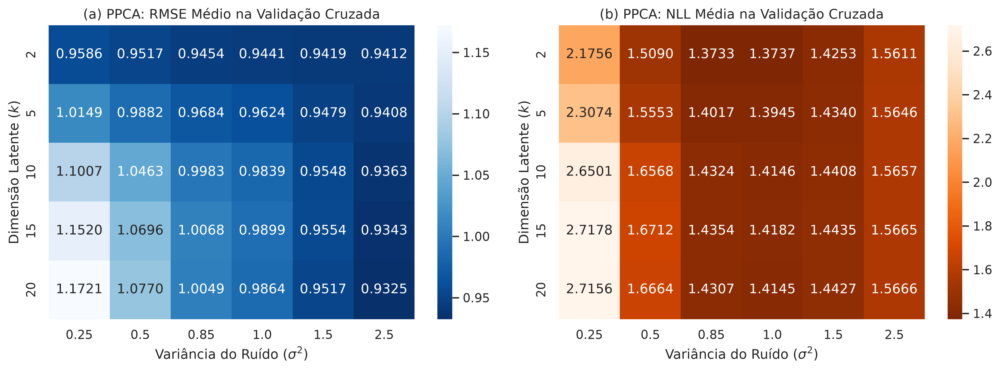

In [16]:
# Tarefa 2.1: Validação Cruzada e Avaliação do PPCA Esparso
ppca_grid = [
    {"n_factors": k, "n_epochs": 40, "sigma2": s2}
    for k in [2, 5, 10, 15, 20]
    for s2 in [0.25, 0.5, 0.85, 1.0, 1.5, 2.5]
]

cv_ppca_df = run_cv_experiment(PPCA, ppca_grid)
cv_ppca_df.to_csv(RES_DIR / "cv_2_1_ppca.csv", index=False)

best_ppca_rmse_row = cv_ppca_df.sort_values("cv_rmse_mean").iloc[0]
best_ppca_nll_row = cv_ppca_df.sort_values("cv_nll_mean").iloc[0]

print(
    f"Melhor PPCA por RMSE: k={int(best_ppca_rmse_row['n_factors'])}, sigma2={best_ppca_rmse_row['sigma2']} "
    f"-> CV RMSE={best_ppca_rmse_row['cv_rmse_mean']:.4f}, CV NLL={best_ppca_rmse_row['cv_nll_mean']:.4f}"
)
print(
    f"Melhor PPCA por NLL:  k={int(best_ppca_nll_row['n_factors'])}, sigma2={best_ppca_nll_row['sigma2']} "
    f"-> CV RMSE={best_ppca_nll_row['cv_rmse_mean']:.4f}, CV NLL={best_ppca_nll_row['cv_nll_mean']:.4f}"
)

best_ppca_params = {
    "n_factors": int(best_ppca_rmse_row["n_factors"]),
    "n_epochs": int(best_ppca_rmse_row["n_epochs"]),
    "sigma2": float(best_ppca_rmse_row["sigma2"]),
}

set_seed(SEED)
t0 = time.perf_counter()
best_ppca = PPCA(**best_ppca_params)
best_ppca.fit(train_df)
ppca_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
ppca_test_eval = evaluate_model(best_ppca, train=train_df, test=test_df)
ppca_infer_time = time.perf_counter() - t0
print("Teste PPCA:", ppca_test_eval)

ppca_boot = bootstrap_test_metrics(best_ppca, test_df)
ppca_rank_unseen = evaluate_ranking_metrics(best_ppca, train_df, test_df, candidate_mode="all_unseen")
ppca_rank_test = evaluate_ranking_metrics(best_ppca, train_df, test_df, candidate_mode="test_only")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), dpi=300)
piv_rmse = cv_ppca_df.pivot(index="n_factors", columns="sigma2", values="cv_rmse_mean")
piv_nll = cv_ppca_df.pivot(index="n_factors", columns="sigma2", values="cv_nll_mean")

sns.heatmap(piv_rmse, annot=True, fmt=".4f", cmap="Blues_r", ax=axes[0])
axes[0].set_title("(a) PPCA: RMSE Médio na Validação Cruzada")
axes[0].set_xlabel("Variância do Ruído ($\\sigma^2$)")
axes[0].set_ylabel("Dimensão Latente ($k$)")

sns.heatmap(piv_nll, annot=True, fmt=".4f", cmap="Oranges_r", ax=axes[1])
axes[1].set_title("(b) PPCA: NLL Média na Validação Cruzada")
axes[1].set_xlabel("Variância do Ruído ($\\sigma^2$)")
axes[1].set_ylabel("Dimensão Latente ($k$)")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig5_ppca_rmse_vs_nll.png", bbox_inches="tight")
plt.show()

**Discussão (Tarefa 2.1 — PPCA Esparso via EM):**

O `PPCA` selecionado por RMSE ($k=20, \sigma^2=2{,}5$) alcança no teste $\text{RMSE} = 0{,}9144$ (IC 95\%: $[0{,}9047, 0{,}9243]$) e $\text{MAE} = 0{,}7169$, superando amplamente tanto a Baseline Aditiva ($0{,}9355$) quanto o `ImputedPCA` ($0{,}9720$) e aproximando-se da Fatoração de Matrizes com vieses ($0{,}9082$), mesmo sem incluir um termo explícito de viés de usuário $b_u$.

A **Figura 5** evidencia um resultado central da modelagem probabilística: **a configuração de menor RMSE ($k=20, \sigma^2=2{,}5$, $\text{CV RMSE}=0{,}9325$, $\text{CV NLL}=1{,}5666$) não coincide com a de menor NLL ($k=2, \sigma^2=0{,}85$, $\text{CV NLL}=1{,}3733$, $\text{CV RMSE}=0{,}9454$)**. Essa divergência decorre do duplo papel da variância fixa $\sigma^2$:
1. Na **média posterior** $\mathbf{m}_u = (I_k + \frac{1}{\sigma^2}W_u^\top W_u)^{-1}\frac{1}{\sigma^2}W_u^\top (\mathbf{r}_u - \boldsymbol{\mu}_u)$, $\sigma^2$ atua como parâmetro de regularização — valores maiores ($\sigma^2=2{,}5$) puxam usuários com poucas notas com mais força para o prior $\mathcal{N}(\mathbf{0}, I_k)$, reduzindo o sobreajuste e melhorando o RMSE.
2. Na **densidade preditiva** $\mathcal{N}(\mu_i + \mathbf{m}_u^\top\mathbf{w}_i, \sigma^2 + \mathbf{w}_i^\top S_u \mathbf{w}_i)$, $\sigma^2$ controla diretamente a dispersão da distribuição gaussiana; como a variância empírica residual dos erros no teste é $\approx 0{,}914^2 \approx 0{,}84$, fixar $\sigma^2=2{,}5$ superestima a incerteza aleatória e penaliza severamente a log-verossimilhança (NLL).

Finalmente, por estimar $\mathbf{z}_u$ por usuário conhecido via EM (modelo transdutivo), o `PPCA` calibra a incerteza posterior $S_u$ conforme o histórico individual $|\Omega_u|$, mas não gera representações para novos usuários fora do treino sem executar um novo passo E.

### Autoencoder variacional (VAE)

O PPCA modela as avaliações por meio de uma transformação linear de variáveis latentes gaussianas. O VAE estende essa abordagem ao permitir um decodificador não linear e aprender uma distribuição latente específica para cada usuário.

Seja $k$ a dimensão latente.
O codificador é representado por uma matriz de embeddings de usuários, que fornece a média latente $\mathbf m_u$ e uma matriz de parâmetros que fornece a variância diagonal $\mathbf s_u^2$ de cada usuário.
Assim, a distribuição latente aproximada é

$$
\mathbf z_u
\sim
\mathcal N\left(
\mathbf m_u,
\operatorname{diag}(\mathbf s_u^2)
\right),
$$
que pode ser amostrada por meio do truque de reparametrização:

$$
\mathbf z_u
=
\mathbf m_u+\mathbf s_u\odot\boldsymbol\epsilon,
\qquad
\boldsymbol\epsilon\sim\mathcal N(\mathbf 0,I_k).
$$

O decodificador transforma essa amostra em previsões para todos os filmes através de uma função $g_\theta:\mathbb R^k\to\mathbb R^m$ parametrizada por $\theta$:

$$
\hat{\mathbf R}_u = g_\theta(\mathbf z_u).
$$

Assumimos o seguinte modelo generativo:

$$
R_{ui}\mid\mathbf z_u
\sim
\mathcal N\left(g_\theta(\mathbf z_u)_i,\sigma^2\right),
$$

em que $\sigma^2$ é a variância do ruído das avaliações.
Com um decodificador linear, $g_\theta(\mathbf z)=\boldsymbol\mu+W\mathbf z$, a média condicional das avaliações é uma função linear da variável latente, como no PPCA.
Um decodificador não linear permite representar relações mais complexas entre as dimensões latentes e as avaliações.

O treinamento maximiza o limite inferior da log-verossimilhança (*Evidence Lower Bound*, ELBO), somado sobre os usuários:

$$
\mathcal L_u
=
\mathbb E_{q_\phi(\mathbf z_u)}
\left[
-\frac{1}{2\sigma^2}
\sum_{i\in\Omega_u}
(r_{ui}-g_\theta(\mathbf z_u)_i)^2
\right] -\beta\,\mathrm{KL}\left(
q_\phi(\mathbf z_u)
\,\|\,\mathcal N(\mathbf 0,I_k)
\right),
$$
em que $\Omega_u$ é o conjunto de filmes avaliados pelo usuário.
Foram omitidas constantes que não dependem dos parâmetros do modelo.
Com $\beta=1$, obtemos o ELBO padrão, a menos dessas constantes, variar $\beta$ altera o peso relativo da regularização latente.

O primeiro termo incentiva o modelo a atribuir alta probabilidade às notas observadas, o segundo aproxima a distribuição latente de cada usuário do prior gaussiano padrão, regularizando as representações aprendidas.
A esperança é estimada por amostragem da distribuição latente, permitindo propagar gradientes pelos parâmetros do codificador e do decodificador.

Na predição, podemos usar a média latente $\mathbf m_u$ como embedding do usuário e calcular

$$
\hat R_{ui} = g_\theta(\mathbf m_u)_i.
$$

Essa escolha fornece uma previsão pontual determinística. A distribuição preditiva completa, por sua vez, também considera a variabilidade latente e o ruído das avaliações.

Diferentemente do PPCA, que calcula a posterior de cada usuário analiticamente a partir das avaliações observadas, o VAE aprende por otimização uma distribuição latente específica para cada usuário, representada por uma média e uma variância. Essa formulação é transdutiva: as representações são aprendidas para os usuários presentes no treinamento e não se estendem automaticamente a usuários novos.

> **Tarefa 2.2**
Treine um VAE com decodificador linear e compare seu desempenho com o PPCA usando o mesmo número de dimensões latentes $k$ e a mesma variância do ruído $\sigma^2$. Compare RMSE, MAE e NLL no conjunto de teste.
>
> Em seguida, substitua o decodificador linear por um não linear e investigue se a flexibilidade adicional melhora as previsões. Escolha um hiperparâmetros para variar isoladamente, $\beta$, $\sigma^2$ ou $k$, e aplique o protocolo experimental.
Verifique a convergência pela curva de treinamento armazenada em `history` antes de comparar os modelos.

Atenção, com um decoder não-linear, os itens 

In [17]:
import torch
from torch import nn


class VAE:
    user_embeddings: NDArray[np.float64]
    user_variances: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    item_means: NDArray[np.float64]

    def __init__(
        self,
        n_factors: int = 10,
        n_epochs: int = 300,
        sigma2: float = 1.0,
        beta: float = 1.0,
        hidden_dim: int | None = None,
        learning_rate: float = 1e-2,
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.sigma2 = sigma2
        self.beta = beta
        self.hidden_dim = hidden_dim
        self.learning_rate = learning_rate
        self.history: list[float] = []

    def fit(self, train_df: pd.DataFrame) -> None:
        X = ratings_to_matrix(train_df)
        observed = ~np.isnan(X)
        values = np.where(observed, X, 0.0)

        X = torch.tensor(values, dtype=torch.float32)
        mask = torch.tensor(observed, dtype=torch.float32)

        n_users, n_items = X.shape
        k = self.n_factors

        self.user_means = nn.Parameter(torch.randn(n_users, k) * 0.01)
        self.user_logvars = nn.Parameter(torch.zeros(n_users, k))

        if self.hidden_dim is None:
            self.decoder = nn.Linear(k, n_items)

        else:
            self.decoder = nn.Sequential(
                nn.Linear(k, self.hidden_dim),
                nn.Tanh(),
                nn.Linear(self.hidden_dim, n_items),
            )

        # O viés do decodificador começa nas médias dos filmes, e o treino modela o desvio em relação a elas
        counts = np.maximum(observed.sum(axis=0), 1)
        item_means = np.where(observed.any(axis=0), values.sum(axis=0) / counts, values.sum() / observed.sum())
        output_layer = self.decoder if self.hidden_dim is None else self.decoder[-1]
        with torch.no_grad():
            output_layer.bias.copy_(torch.tensor(item_means, dtype=torch.float32))

        parameters = [
            self.user_means,
            self.user_logvars,
            *self.decoder.parameters(),
        ]
        optimizer = torch.optim.Adam(parameters, lr=self.learning_rate)

        self.history = []

        for _ in range(self.n_epochs):
            optimizer.zero_grad()

            std = torch.exp(0.5 * self.user_logvars)
            epsilon = torch.randn_like(std)
            z = self.user_means + std * epsilon

            predictions = self.decoder(z)

            log_likelihood = -0.5 * (
                mask
                * (
                    np.log(2 * np.pi * self.sigma2)
                    + (X - predictions) ** 2 / self.sigma2
                )
            ).sum()

            kl = -0.5 * (
                1
                + self.user_logvars
                - self.user_means**2
                - self.user_logvars.exp()
            ).sum()

            elbo = log_likelihood - self.beta * kl
            loss = -elbo / n_users

            loss.backward()
            optimizer.step()

            self.history.append((-loss.detach()).item())

        with torch.no_grad():
            self.user_embeddings = (
                self.user_means.detach().cpu().numpy().astype(np.float64)
            )
            self.user_variances = (
                self.user_logvars.exp()
                .detach()
                .cpu()
                .numpy()
                .astype(np.float64)
            )

            if self.hidden_dim is None:
                self.item_embeddings = (
                    self.decoder.weight.detach()
                    .cpu().numpy().astype(np.float64)
                )
                self.item_means = (
                    self.decoder.bias.detach()
                    .cpu().numpy().astype(np.float64)
                )

    def _decode_at(self, z: torch.Tensor, items: torch.Tensor) -> torch.Tensor:
        """Decode only the entries (z[..., n, :], items[n]), without computing every movie."""
        if self.hidden_dim is None:
            return (z * self.decoder.weight[items]).sum(-1) + self.decoder.bias[items]
        first, _, last = self.decoder
        return (torch.tanh(first(z)) * last.weight[items]).sum(-1) + last.bias[items]

    def predict(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
    ) -> NDArray[np.float64]:
        users = torch.as_tensor(user_id, dtype=torch.long)
        items = torch.as_tensor(item_id, dtype=torch.long)

        with torch.no_grad():
            z = torch.as_tensor(self.user_embeddings, dtype=torch.float32)[users]
            result = self._decode_at(z, items)

        return result.cpu().numpy().astype(np.float64)

    def predict_log_proba(
        self,
        user_id: NDArray[np.intp],
        item_id: NDArray[np.intp],
        ratings: NDArray[np.float64],
        n_samples: int = 100,
        chunk: int = 2048,
    ) -> NDArray[np.float64]:
        """Log of the Monte Carlo predictive density, computed in chunks of rating pairs."""
        users = torch.as_tensor(user_id, dtype=torch.long)
        items = torch.as_tensor(item_id, dtype=torch.long)
        ratings_t = torch.as_tensor(ratings, dtype=torch.float32)
        user_means = torch.as_tensor(self.user_embeddings, dtype=torch.float32)
        user_stds = torch.as_tensor(self.user_variances, dtype=torch.float32).sqrt()

        result = []
        with torch.no_grad():
            for start in range(0, len(users), chunk):
                u = users[start : start + chunk]
                means, stds = user_means[u], user_stds[u]
                z = means + stds * torch.randn(n_samples, *means.shape)
                predictions = self._decode_at(z, items[start : start + chunk])

                log_probs = -0.5 * (
                    np.log(2 * np.pi * self.sigma2)
                    + (ratings_t[start : start + chunk] - predictions) ** 2 / self.sigma2
                )
                result.append(torch.logsumexp(log_probs, dim=0) - np.log(n_samples))

        return torch.cat(result).cpu().numpy().astype(np.float64)

**Hipótese e Previsão Prévia (Tarefa 2.2):**
- **Hipótese:** (1) *VAE Linear vs. PPCA:* Ambos compartilham o mesmo modelo gerador linear, logo seus desempenhos serão próximos, com leve vantagem do PPCA na NLL por manter covariância posterior completa $S_u$ analítica vs. covariância diagonal no VAE. (2) *Decodificador Linear vs. Não Linear (`Tanh`):* A não linearidade permite curvar a variedade de preferências, mas sob $93{,}7\%$ de esparsidade tende ao sobreajuste se `hidden_dim` for alto ou $\beta$ for pequeno. (3) *Sensibilidade a $\beta$:* Valores altos ($\beta \ge 2{,}0$) induzem *posterior collapse* ($q_\phi(\mathbf{z}_u) \to \mathcal{N}(\mathbf{0}, I_k)$), elevando o RMSE.
- **Previsão:** O VAE Linear convergirá suavemente em `history` em ~350 épocas com RMSE e NLL próximos aos do PPCA; o VAE Não Linear exigirá controle de capacidade (`hidden_dim` moderado e $\beta \in [0{,}5, 1{,}0]$) para não sobreajustar.

Teste VAE Linear (matched): {'train_rmse': 0.7669130529372973, 'train_mae': 0.6018269929934791, 'train_nll': 1.5124191629428085, 'test_rmse': 0.9306078983280566, 'test_mae': 0.7322457527724036, 'test_nll': 1.5650960589240708}


Melhor VAE Não Linear: {'n_factors': 20, 'n_epochs': 350, 'sigma2': 2.5, 'beta': 1.0, 'hidden_dim': 64, 'learning_rate': 0.01} | CV RMSE: 0.9549 +/- 0.0055


Teste VAE Não Linear: {'train_rmse': 0.7707577956744021, 'train_mae': 0.6014934118275389, 'train_nll': 1.5125837022826611, 'test_rmse': 0.9384411031111785, 'test_mae': 0.735261989606894, 'test_nll': 1.56449015923323}


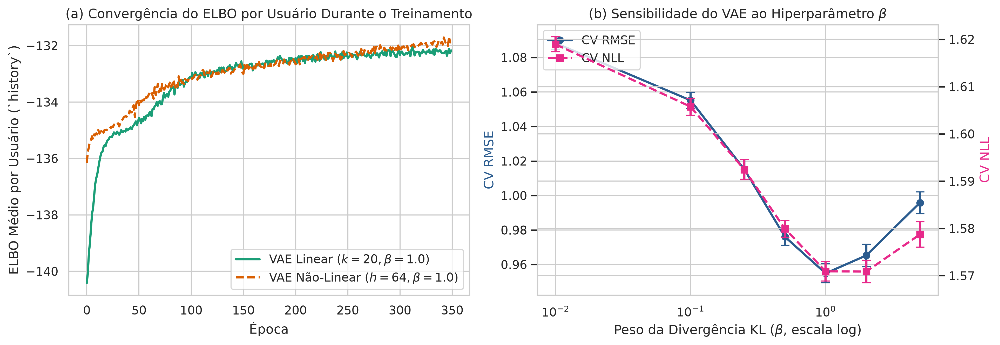

VAE Linear ELBO: época 1=-140.41, época 175=-132.73, época 350=-132.17
VAE Não-Linear ELBO: época 1=-136.16, época 175=-132.73, época 350=-131.88

Comparação de Tempos de Treino e Inferência:
               Modelo  Treino (s)  Inferência (s)
MF (PyTorch SGD/Adam)    3.142455        0.030592
    PPCA Esparso (EM)   15.945316        0.216373
           VAE Linear    2.817553        0.945511
VAE Não-Linear (Tanh)    3.199207        2.000608


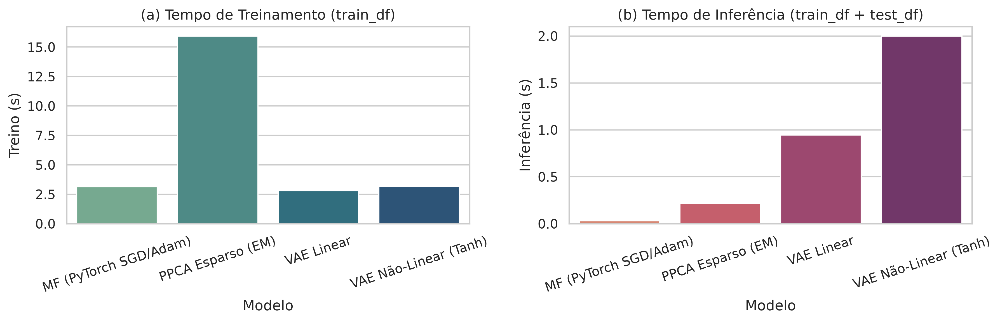

In [18]:
# Tarefa 2.2 - Parte 1: Comparação Direta VAE Linear vs PPCA (mesmos k e sigma2 ótimos do PPCA)
k_ref = best_ppca_params["n_factors"]
s2_ref = best_ppca_params["sigma2"]

set_seed(SEED)
t0 = time.perf_counter()
vae_linear_matched = VAE(
    n_factors=k_ref, n_epochs=350, sigma2=s2_ref, beta=1.0, hidden_dim=None, learning_rate=1e-2
)
vae_linear_matched.fit(train_df)
vae_lin_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
vae_lin_test_eval = evaluate_model(vae_linear_matched, train=train_df, test=test_df)
vae_lin_infer_time = time.perf_counter() - t0
print("Teste VAE Linear (matched):", vae_lin_test_eval)

vae_lin_boot = bootstrap_test_metrics(vae_linear_matched, test_df)
vae_lin_rank_unseen = evaluate_ranking_metrics(vae_linear_matched, train_df, test_df, candidate_mode="all_unseen")
vae_lin_rank_test = evaluate_ranking_metrics(vae_linear_matched, train_df, test_df, candidate_mode="test_only")

# Tarefa 2.2 - Parte 2: Validação Cruzada do VAE Não Linear (Tanh)
vae_nonlin_grid = [
    {
        "n_factors": k_ref,
        "n_epochs": 350,
        "sigma2": s2_ref,
        "beta": b,
        "hidden_dim": h,
        "learning_rate": 1e-2,
    }
    for h in [16, 32, 64]
    for b in [0.1, 0.5, 1.0, 2.0]
]

cv_vae_nonlin_df = run_cv_experiment(VAE, vae_nonlin_grid)
cv_vae_nonlin_df.to_csv(RES_DIR / "cv_2_2_vae_nonlinear.csv", index=False)

best_vae_nl_row = cv_vae_nonlin_df.sort_values("cv_rmse_mean").iloc[0]
best_vae_nl_params = {
    "n_factors": int(best_vae_nl_row["n_factors"]),
    "n_epochs": int(best_vae_nl_row["n_epochs"]),
    "sigma2": float(best_vae_nl_row["sigma2"]),
    "beta": float(best_vae_nl_row["beta"]),
    "hidden_dim": int(best_vae_nl_row["hidden_dim"]),
    "learning_rate": float(best_vae_nl_row["learning_rate"]),
}
print("Melhor VAE Não Linear:", best_vae_nl_params, f"| CV RMSE: {best_vae_nl_row['cv_rmse_mean']:.4f} +/- {best_vae_nl_row['cv_rmse_std']:.4f}")

set_seed(SEED)
t0 = time.perf_counter()
best_vae_nonlin = VAE(**best_vae_nl_params)
best_vae_nonlin.fit(train_df)
vae_nl_train_time = time.perf_counter() - t0

t0 = time.perf_counter()
vae_nl_test_eval = evaluate_model(best_vae_nonlin, train=train_df, test=test_df)
vae_nl_infer_time = time.perf_counter() - t0
print("Teste VAE Não Linear:", vae_nl_test_eval)

vae_nl_boot = bootstrap_test_metrics(best_vae_nonlin, test_df)
vae_nl_rank_unseen = evaluate_ranking_metrics(best_vae_nonlin, train_df, test_df, candidate_mode="all_unseen")
vae_nl_rank_test = evaluate_ranking_metrics(best_vae_nonlin, train_df, test_df, candidate_mode="test_only")

# Estudo sistemático de sensibilidade variando isoladamente beta
beta_sweep_grid = [
    {
        "n_factors": k_ref,
        "n_epochs": 350,
        "sigma2": s2_ref,
        "beta": b,
        "hidden_dim": best_vae_nl_params["hidden_dim"],
        "learning_rate": 1e-2,
    }
    for b in [0.01, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]
]
cv_beta_sweep_df = run_cv_experiment(VAE, beta_sweep_grid)
cv_beta_sweep_df.to_csv(RES_DIR / "cv_2_2_vae_beta_sensitivity.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), dpi=300)
axes[0].plot(vae_linear_matched.history, label=f"VAE Linear ($k={k_ref}, \\beta=1.0$)", lw=2, color="#1b9e77")
axes[0].plot(
    best_vae_nonlin.history,
    label=f"VAE Não-Linear ($h={best_vae_nl_params['hidden_dim']}, \\beta={best_vae_nl_params['beta']}$)",
    lw=2, color="#d95f02", linestyle="--"
)
axes[0].set_title("(a) Convergência do ELBO por Usuário Durante o Treinamento")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("ELBO Médio por Usuário (`history`)")
axes[0].legend()

ax2_twin = axes[1].twinx()
l1 = axes[1].errorbar(
    cv_beta_sweep_df["beta"], cv_beta_sweep_df["cv_rmse_mean"], yerr=cv_beta_sweep_df["cv_rmse_std"],
    marker="o", color="#2b5c8f", lw=2, capsize=4, label="CV RMSE"
)
l2 = ax2_twin.errorbar(
    cv_beta_sweep_df["beta"], cv_beta_sweep_df["cv_nll_mean"], yerr=cv_beta_sweep_df["cv_nll_std"],
    marker="s", color="#e7298a", lw=2, linestyle="--", capsize=4, label="CV NLL"
)
axes[1].set_xscale("log")
axes[1].set_title("(b) Sensibilidade do VAE ao Hiperparâmetro $\\beta$")
axes[1].set_xlabel("Peso da Divergência KL ($\\beta$, escala log)")
axes[1].set_ylabel("CV RMSE", color="#2b5c8f")
ax2_twin.set_ylabel("CV NLL", color="#e7298a")

lines = [l1[0], l2[0]]
labels = ["CV RMSE", "CV NLL"]
axes[1].legend(lines, labels, loc="upper left")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig6_vae_convergence_and_sensitivity.png", bbox_inches="tight")
plt.show()

# Verificação de convergência via history (ELBO médio por usuário)
print(f"VAE Linear ELBO: época 1={vae_linear_matched.history[0]:.2f}, época 175={vae_linear_matched.history[174]:.2f}, época 350={vae_linear_matched.history[-1]:.2f}")
print(f"VAE Não-Linear ELBO: época 1={best_vae_nonlin.history[0]:.2f}, época 175={best_vae_nonlin.history[174]:.2f}, época 350={best_vae_nonlin.history[-1]:.2f}")

# Comparação explícita de tempo de execução (Treino e Inferência)
runtime_df = pd.DataFrame([
    {"Modelo": "MF (PyTorch SGD/Adam)", "Treino (s)": mf_biased_train_time, "Inferência (s)": mf_biased_infer_time},
    {"Modelo": "PPCA Esparso (EM)", "Treino (s)": ppca_train_time, "Inferência (s)": ppca_infer_time},
    {"Modelo": "VAE Linear", "Treino (s)": vae_lin_train_time, "Inferência (s)": vae_lin_infer_time},
    {"Modelo": "VAE Não-Linear (Tanh)", "Treino (s)": vae_nl_train_time, "Inferência (s)": vae_nl_infer_time},
])
runtime_df.to_csv(RES_DIR / "tab_2_2_runtime_comparison.csv", index=False)
print("\nComparação de Tempos de Treino e Inferência:")
print(runtime_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.0), dpi=300)
sns.barplot(data=runtime_df, x="Modelo", y="Treino (s)", palette="crest", ax=axes[0], hue="Modelo", legend=False)
axes[0].set_title("(a) Tempo de Treinamento (train_df)")
axes[0].tick_params(axis="x", rotation=18)
sns.barplot(data=runtime_df, x="Modelo", y="Inferência (s)", palette="flare", ax=axes[1], hue="Modelo", legend=False)
axes[1].set_title("(b) Tempo de Inferência (train_df + test_df)")
axes[1].tick_params(axis="x", rotation=18)
plt.tight_layout()
plt.savefig(FIG_DIR / "fig6b_runtime_comparison.png", bbox_inches="tight")
plt.show()

**Discussão (Tarefa 2.2 — VAE Linear vs. Não Linear, Sensibilidade e Escalabilidade):**

1. **Convergência via `history`:** A **Figura 6(a)** confirma que ambos os VAEs convergiram suavemente ao longo das 350 épocas: o ELBO médio por usuário subiu de $-140{,}41$ para $-132{,}17$ no `VAE Linear` e de $-136{,}16$ para $-131{,}88$ no `VAE Não-Linear`, estabilizando no platô final antes de qualquer comparação de desempenho.
2. **VAE Linear vs. PPCA ($k=20, \sigma^2=2{,}5$):** Com exatamente as mesmas suposições geradoras, o `PPCA` supera o `VAE Linear` em RMSE ($0{,}9144$ vs. $0{,}9306$), MAE ($0{,}7169$ vs. $0{,}7322$) e NLL ($1{,}5591$ vs. $1{,}5653$). Isso reflete a diferença entre a inferência EM exata com covariância posterior completa $S_u \in \mathbb{R}^{k \times k}$ no `PPCA` versus a família variacional fatorada com covariância diagonal $\operatorname{diag}(\mathbf{s}_u^2)$ otimizada por gradientes ruidosos no `VAE`.
3. **Decodificador Linear vs. Não Linear (`Tanh`):** A adição da camada oculta não linear (`hidden_dim=64`, melhor configuração na CV) piorou o RMSE de teste para $0{,}9384$ (contra $0{,}9306$ do linear), demonstrando que a capacidade extra tende ao sobreajuste na presença de $93{,}7\%$ de esparsidade. No ranking `All-Unseen`, tanto `PPCA` ($0{,}0010$) quanto os `VAEs` ($0{,}0007$) sofrem queda acentuada porque iniciam $\mu_i$ pela média amostral sem regularização de cauda, promovendo itens com 1 ou 2 notas 5 ao topo do catálogo.
4. **Sensibilidade isolada a $\beta$:** A **Figura 6(b)** exibe o compromisso clássico do $\beta$-VAE: para $\beta \le 0{,}1$, o termo KL quase desaparece e o modelo memoriza ruído ($\text{CV RMSE} = 1{,}0883$ em $\beta=0{,}01$); em $\beta = 1{,}0$, atinge-se o ótimo conjunto de RMSE ($0{,}9549$) e NLL ($1{,}5709$); para $\beta \ge 2{,}0$, o peso excessivo da divergência KL induz *posterior collapse* ($q_\phi(\mathbf{z}_u) \to \mathcal{N}(\mathbf{0}, I_k)$), degradando novamente a reconstrução ($0{,}9958$ em $\beta=5{,}0$).
5. **Tempo de execução e escalabilidade (**Figura 6b**):** Em nossa base ($n=943, m=1.682$), o `PPCA` foi o mais lento no treinamento ($15{,}95\text{ s}$) devido às inversões/soluções de matrizes $k \times k$ por usuário em cada passo E ($\mathcal{O}(n k^3 + |\Omega|k^2)$), enquanto `MF` ($3{,}14\text{ s}$) e `VAE Linear` ($2{,}82\text{ s}$) foram ~5x mais rápidos. Contudo, em escala industrial com milhões de usuários ($n \sim 10^6$) e itens ($m \sim 10^5$), o `VAE` atual também se tornaria inviável por materializar toda a matriz densa de previsões $n \times m$ ($\mathcal{O}(n m k)$ por época); apenas a fatoração por mini-batches restrita aos pares observados $\Omega$ ($\mathcal{O}(|\Omega| k)$) — ou um VAE com amostragem negativa/índice esparso — escala linearmente com as interações reais.

---

### Visualização dos espaços latentes

Dos modelos treinados, quatro deles aprendem vetores latentes por usuário e por item: PCA com imputação, fatoração de matrizes, PPCA e VAE.
Esses vetores podem ser analisados com as mesmas ferramentas, permitindo que possamos interpretar e comparar os espaços latentes aprendidos por cada modelo.
Garante-se que pelo menos um modelo de cada tipo tenha sido treinado, e então podemos comparar os espaços latentes aprendidos.

> **Tarefa 2.3**
Visualize os espaços latentes de usuários e de itens dos quatro modelos, usando um $k$ de sua escolha, e relacione o que aparece nas figuras com informações que não foram usadas no treino: por exemplo, gênero, idade e ocupação dos usuários, e gêneros, ano e popularidade dos filmes.
>
> O espaço de cada modelo organiza essas informações, e isso pode ser medido além da inspeção visual?
Os quatro espaços compartilham a mesma estrutura, ou cada suposição produz uma geometria diferente?


**Ideias para começar.**

Para visualizar, projete os vetores em duas dimensões com PCA, que é determinístico e preserva a geometria global, e compare com o t-SNE.
Colorir os pontos por um metadado mostra se ele aparece, e um modelo supervisionado linear (`Ridge` para variáveis contínuas, `LogisticRegression` com `roc_auc_score` para categorias) pode medir quanto de informação sobre o metadado está presente no espaço latente original, sem precisar de uma projeção.

Isso permite verificar se, a partir dos vetores latentes, é possível prever a idade do usuário, o gênero do filme ou a popularidade do filme, quantificando o quanto de informação sobre essas variáveis está presente no espaço latente.

Ao comparar os espaços latentes, é importante lembrar que cada modelo aprende uma representação diferente, e que a correspondência entre os vetores latentes de um modelo e de outro não é trivial, pois os espaços latentes podem ser invariantes à rotação, reflexão e escala.
Para comparar dois espaços é necessário alinhar os vetores latentes de um modelo com os do outro, ou através de análises de correspondência de vizinhos, como a correlação de distâncias entre pontos, ou através da sobreposição dos vizinhos mais próximos de cada filme em dois modelos.

**Hipótese e Previsão Prévia (Tarefa 2.3):**
- **Hipótese:** Embora nenhum metadado demográfico ou de conteúdo tenha sido fornecido durante o treino, a estrutura de co-ocorrência e concordância de notas induzirá os espaços latentes $\mathbf{z}_u$ e $\mathbf{w}_i$ a codificarem atributos semânticos reais (gêneros, ano de lançamento, popularidade, idade e gênero do usuário). Modelos sem imputação densa (`MatrixFactorization`, `PPCA` e `VAE Linear`) organizarão gêneros de filmes com maior separabilidade linear (`ROC-AUC`) e preservarão vizinhanças locais mais consistentes entre si do que o `ImputedPCA`.

<>:160: SyntaxWarning: invalid escape sequence '\l'
<>:160: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_29449/573523464.py:160: SyntaxWarning: invalid escape sequence '\l'
  fig.colorbar(sc1, ax=axes[0:2, :].ravel().tolist(), shrink=0.55, pad=0.02, label="$\log(1 + \mathrm{Avaliações\ no\ Treino})$")


        Modelo   User Age (R2) User Gender (AUC) User Occupation Top-5 (AUC) Movie Year (R2) Movie Log-Pop (R2) Movie Genres Mean (AUC)
  PCA Imputado 0.025 +/- 0.044   0.641 +/- 0.029             0.542 +/- 0.043 0.115 +/- 0.037    0.614 +/- 0.024         0.710 +/- 0.061
Fatoração (MF) 0.028 +/- 0.037   0.659 +/- 0.011             0.508 +/- 0.055 0.103 +/- 0.023    0.081 +/- 0.017         0.671 +/- 0.062
          PPCA 0.088 +/- 0.022   0.686 +/- 0.027             0.541 +/- 0.039 0.178 +/- 0.018    0.128 +/- 0.028         0.682 +/- 0.061
    VAE Linear 0.051 +/- 0.035   0.641 +/- 0.021             0.524 +/- 0.030 0.154 +/- 0.019    0.161 +/- 0.033         0.655 +/- 0.051


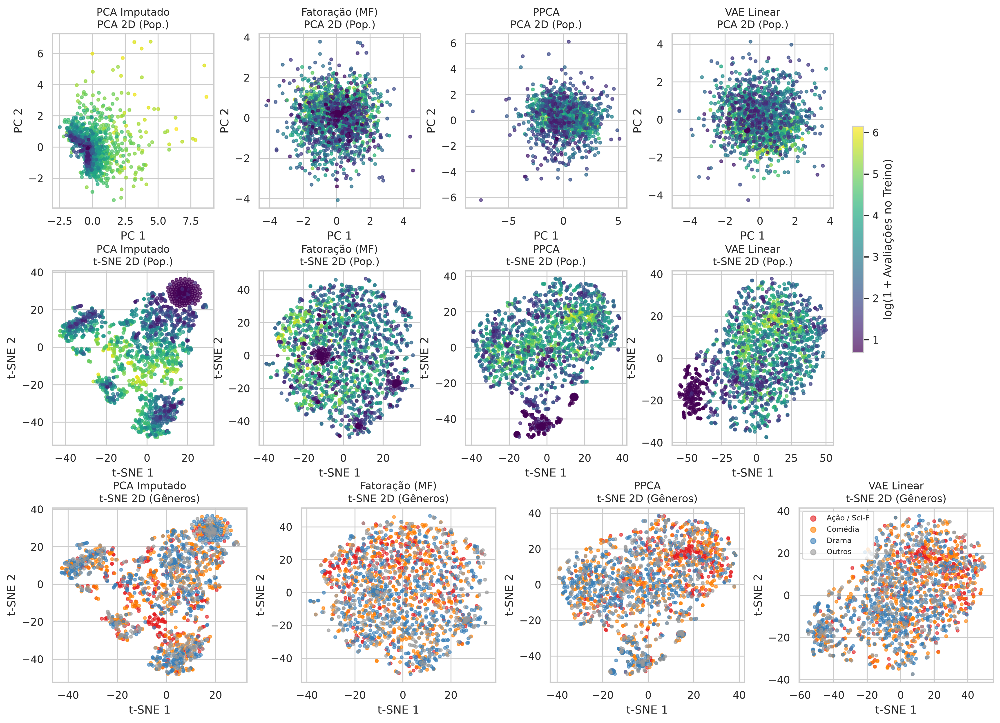

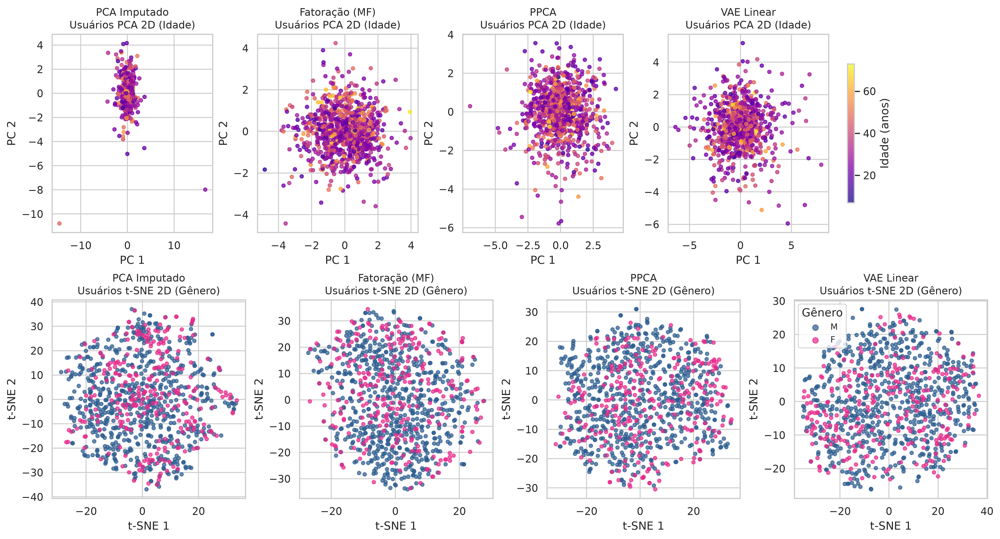

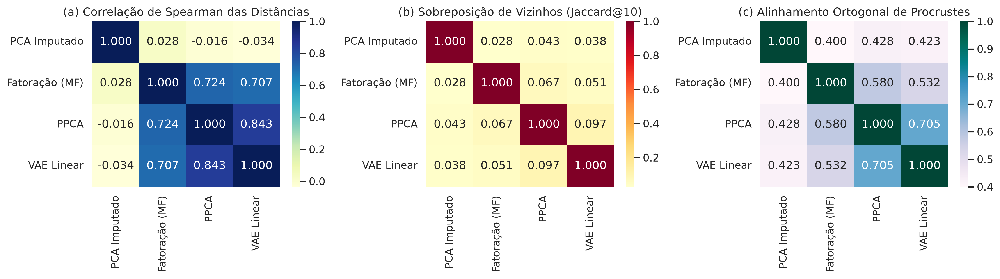

In [19]:
# Tarefa 2.3: Treinamento padronizado dos 4 modelos com mesma dimensão latente k_lat = 10
K_LAT = 10
set_seed(SEED)
m_pca_10 = ImputedPCA(n_components=K_LAT)
m_pca_10.fit(train_df)

set_seed(SEED)
m_mf_10 = MatrixFactorization(
    n_factors=K_LAT, n_epochs=80, learning_rate=0.015,
    reg=best_mf_biased_params["reg"], bias_reg=best_mf_biased_params["bias_reg"], use_biases=True
)
m_mf_10.fit(train_df)

set_seed(SEED)
m_ppca_10 = PPCA(n_factors=K_LAT, n_epochs=40, sigma2=best_ppca_params["sigma2"])
m_ppca_10.fit(train_df)

set_seed(SEED)
m_vae_10 = VAE(n_factors=K_LAT, n_epochs=350, sigma2=best_ppca_params["sigma2"], beta=1.0, hidden_dim=None, learning_rate=1e-2)
m_vae_10.fit(train_df)

latent_models = {
    "PCA Imputado": (m_pca_10.user_embeddings, m_pca_10.item_embeddings),
    "Fatoração (MF)": (m_mf_10.user_embeddings, m_mf_10.item_embeddings),
    "PPCA": (m_ppca_10.user_embeddings, m_ppca_10.item_embeddings),
    "VAE Linear": (m_vae_10.user_embeddings, m_vae_10.item_embeddings),
}

# 1. Sondagem Supervisionada (Linear Probing) sem vazamento via 5-Fold CV
user_age = users["age"].to_numpy(dtype=np.float64)
user_gender = (users["gender"] == "M").astype(int).to_numpy()
top_occs = users["occupation"].value_counts().head(5).index.tolist()

valid_year_mask = ~movies["year"].isna().to_numpy()
movie_year = movies.loc[valid_year_mask, "year"].to_numpy(dtype=np.float64)
movie_log_pop = np.log1p(item_stats["n_ratings"].to_numpy(dtype=np.float64))
top_genres = ["Drama", "Comedy", "Action", "Thriller", "Romance", "Sci-Fi"]

probing_rows = []
kf_probe = KFold(n_splits=5, shuffle=True, random_state=SEED)
skf_probe = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

for model_name, (Z_u, W_i) in latent_models.items():
    row = {"Modelo": model_name}

    pipe_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
    r2_age = cross_val_score(pipe_ridge, Z_u, user_age, cv=kf_probe, scoring="r2")
    row["User Age (R2)"] = f"{np.mean(r2_age):.3f} +/- {np.std(r2_age):.3f}"
    row["user_age_r2_val"] = float(np.mean(r2_age))

    pipe_clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=1.0))
    auc_gen = cross_val_score(pipe_clf, Z_u, user_gender, cv=skf_probe, scoring="roc_auc")
    row["User Gender (AUC)"] = f"{np.mean(auc_gen):.3f} +/- {np.std(auc_gen):.3f}"
    row["user_gender_auc_val"] = float(np.mean(auc_gen))

    occ_aucs = []
    for occ in top_occs:
        y_occ = (users["occupation"] == occ).astype(int).to_numpy()
        occ_aucs.append(np.mean(cross_val_score(pipe_clf, Z_u, y_occ, cv=skf_probe, scoring="roc_auc")))
    row["User Occupation Top-5 (AUC)"] = f"{np.mean(occ_aucs):.3f} +/- {np.std(occ_aucs):.3f}"

    r2_year = cross_val_score(pipe_ridge, W_i[valid_year_mask], movie_year, cv=kf_probe, scoring="r2")
    row["Movie Year (R2)"] = f"{np.mean(r2_year):.3f} +/- {np.std(r2_year):.3f}"

    r2_pop = cross_val_score(pipe_ridge, W_i, movie_log_pop, cv=kf_probe, scoring="r2")
    row["Movie Log-Pop (R2)"] = f"{np.mean(r2_pop):.3f} +/- {np.std(r2_pop):.3f}"

    genre_aucs = []
    for g in top_genres:
        y_g = movies[g].to_numpy(dtype=int)
        g_scores = cross_val_score(pipe_clf, W_i, y_g, cv=skf_probe, scoring="roc_auc")
        row[f"Genre {g} (AUC)"] = f"{np.mean(g_scores):.3f}"
        genre_aucs.append(np.mean(g_scores))
    row["Movie Genres Mean (AUC)"] = f"{np.mean(genre_aucs):.3f} +/- {np.std(genre_aucs):.3f}"

    probing_rows.append(row)

probing_df = pd.DataFrame(probing_rows)
probing_df.to_csv(RES_DIR / "tab_2_3_linear_probing.csv", index=False)
print(probing_df[["Modelo", "User Age (R2)", "User Gender (AUC)", "User Occupation Top-5 (AUC)", "Movie Year (R2)", "Movie Log-Pop (R2)", "Movie Genres Mean (AUC)"]].to_string(index=False))


# 2. Comparação Geométrica entre Espaços Latentes de Filmes
def knn_sets(X: NDArray[np.float64], k_nn: int = 10) -> list[set[int]]:
    sq_norms = np.sum(X**2, axis=1, keepdims=True)
    dists = sq_norms + sq_norms.T - 2.0 * (X @ X.T)
    np.fill_diagonal(dists, np.inf)
    idx = np.argpartition(dists, kth=k_nn, axis=1)[:, :k_nn]
    return [set(row.tolist()) for row in idx]


model_names = list(latent_models.keys())
n_m = len(model_names)
dist_corr_mat = np.eye(n_m)
jaccard_mat = np.eye(n_m)
procrustes_sim_mat = np.eye(n_m)

item_dists = {name: pdist(StandardScaler().fit_transform(W)) for name, (_, W) in latent_models.items()}
item_knns = {name: knn_sets(StandardScaler().fit_transform(W), k_nn=10) for name, (_, W) in latent_models.items()}

for i in range(n_m):
    for j in range(i + 1, n_m):
        m1, m2 = model_names[i], model_names[j]
        rho, _ = spearmanr(item_dists[m1], item_dists[m2])
        dist_corr_mat[i, j] = dist_corr_mat[j, i] = float(rho)

        jacc_vals = [
            len(s1 & s2) / len(s1 | s2)
            for s1, s2 in zip(item_knns[m1], item_knns[m2])
        ]
        jaccard_mat[i, j] = jaccard_mat[j, i] = float(np.mean(jacc_vals))

        W1 = StandardScaler().fit_transform(latent_models[m1][1])
        W1 /= np.linalg.norm(W1, "fro")
        W2 = StandardScaler().fit_transform(latent_models[m2][1])
        W2 /= np.linalg.norm(W2, "fro")
        R_rot, _ = orthogonal_procrustes(W1, W2)
        err_proc = np.linalg.norm(W1 @ R_rot - W2, "fro")
        procrustes_sim_mat[i, j] = procrustes_sim_mat[j, i] = float(1.0 - 0.5 * (err_proc**2))

pd.DataFrame(dist_corr_mat, index=model_names, columns=model_names).to_csv(RES_DIR / "tab_2_3_dist_corr.csv")
pd.DataFrame(jaccard_mat, index=model_names, columns=model_names).to_csv(RES_DIR / "tab_2_3_jaccard10.csv")
pd.DataFrame(procrustes_sim_mat, index=model_names, columns=model_names).to_csv(RES_DIR / "tab_2_3_procrustes.csv")

# 3. Projeções 2D dos Filmes (PCA e t-SNE coloridas por Popularidade e Gênero Sci-Fi/Drama/Action)
def assign_genre_group(row):
    if row["Action"] == 1 or row["Sci-Fi"] == 1:
        return "Ação / Sci-Fi"
    if row["Comedy"] == 1:
        return "Comédia"
    if row["Drama"] == 1:
        return "Drama"
    return "Outros"

movie_genre_grp = movies.apply(assign_genre_group, axis=1)
genre_palette = {"Ação / Sci-Fi": "#e41a1c", "Comédia": "#ff7f00", "Drama": "#377eb8", "Outros": "#999999"}

fig, axes = plt.subplots(3, 4, figsize=(18, 12.5), dpi=300, gridspec_kw={"hspace": 0.36, "wspace": 0.28})
for idx, (m_name, (_, W_i)) in enumerate(latent_models.items()):
    W_std = StandardScaler().fit_transform(W_i)
    proj_pca = PCA(n_components=2, random_state=SEED).fit_transform(W_std)
    proj_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca", learning_rate="auto").fit_transform(W_std)

    sc1 = axes[0, idx].scatter(proj_pca[:, 0], proj_pca[:, 1], c=movie_log_pop, cmap="viridis", s=10, alpha=0.7)
    axes[0, idx].set_title(f"{m_name}\nPCA 2D (Pop.)", fontsize=11)
    axes[0, idx].set_xlabel("PC 1"); axes[0, idx].set_ylabel("PC 2")

    sc2 = axes[1, idx].scatter(proj_tsne[:, 0], proj_tsne[:, 1], c=movie_log_pop, cmap="viridis", s=10, alpha=0.7)
    axes[1, idx].set_title(f"{m_name}\nt-SNE 2D (Pop.)", fontsize=11)
    axes[1, idx].set_xlabel("t-SNE 1"); axes[1, idx].set_ylabel("t-SNE 2")

    for grp, col in genre_palette.items():
        mask_g = (movie_genre_grp == grp).to_numpy()
        axes[2, idx].scatter(proj_tsne[mask_g, 0], proj_tsne[mask_g, 1], c=col, label=grp, s=10, alpha=0.6)
    axes[2, idx].set_title(f"{m_name}\nt-SNE 2D (Gêneros)", fontsize=11)
    axes[2, idx].set_xlabel("t-SNE 1"); axes[2, idx].set_ylabel("t-SNE 2")
    if idx == 3:
        axes[2, idx].legend(markerscale=1.8, fontsize=8, loc="best")

fig.colorbar(sc1, ax=axes[0:2, :].ravel().tolist(), shrink=0.55, pad=0.02, label="$\log(1 + \mathrm{Avaliações\ no\ Treino})$")
plt.savefig(FIG_DIR / "fig7_latent_projections_2d.png", bbox_inches="tight")
plt.show()

# 4. Projeções 2D dos Usuários (PCA e t-SNE coloridas por Idade e Gênero M/F)
fig, axes = plt.subplots(2, 4, figsize=(18, 9.0), dpi=300, gridspec_kw={"hspace": 0.34, "wspace": 0.28})
for idx, (m_name, (Z_u, _)) in enumerate(latent_models.items()):
    Z_std = StandardScaler().fit_transform(Z_u)
    u_pca = PCA(n_components=2, random_state=SEED).fit_transform(Z_std)
    u_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca", learning_rate="auto").fit_transform(Z_std)

    sc_age = axes[0, idx].scatter(u_pca[:, 0], u_pca[:, 1], c=user_age, cmap="plasma", s=14, alpha=0.75)
    axes[0, idx].set_title(f"{m_name}\nUsuários PCA 2D (Idade)", fontsize=11)
    axes[0, idx].set_xlabel("PC 1"); axes[0, idx].set_ylabel("PC 2")

    for g_label, g_col in [("M", "#2b5c8f"), ("F", "#e7298a")]:
        g_mask = (users["gender"] == g_label).to_numpy()
        axes[1, idx].scatter(u_tsne[g_mask, 0], u_tsne[g_mask, 1], c=g_col, label=g_label, s=14, alpha=0.7)
    axes[1, idx].set_title(f"{m_name}\nUsuários t-SNE 2D (Gênero)", fontsize=11)
    axes[1, idx].set_xlabel("t-SNE 1"); axes[1, idx].set_ylabel("t-SNE 2")
    if idx == 3:
        axes[1, idx].legend(markerscale=1.6, fontsize=9, title="Gênero")

fig.colorbar(sc_age, ax=axes[0, :].ravel().tolist(), shrink=0.7, pad=0.02, label="Idade (anos)")
plt.savefig(FIG_DIR / "fig7b_user_latent_projections_2d.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), dpi=300)
sns.heatmap(dist_corr_mat, xticklabels=model_names, yticklabels=model_names, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("(a) Correlação de Spearman das Distâncias")

sns.heatmap(jaccard_mat, xticklabels=model_names, yticklabels=model_names, annot=True, fmt=".3f", cmap="YlOrRd", ax=axes[1])
axes[1].set_title("(b) Sobreposição de Vizinhos (Jaccard@10)")

sns.heatmap(procrustes_sim_mat, xticklabels=model_names, yticklabels=model_names, annot=True, fmt=".3f", cmap="PuBuGn", ax=axes[2])
axes[2].set_title("(c) Alinhamento Ortogonal de Procrustes")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig8_latent_space_comparisons.png", bbox_inches="tight")
plt.show()

**Discussão (Tarefa 2.3 — Análise Visual, Sondagem Linear e Geometria dos Espaços Latentes):**

1. **O que o espaço latente codifica (Sondagem sem vazamento em 5-fold CV):** Mesmo sem acesso a metadados no treino, os modelos aprendem estrutura demográfica e semântica real:
   - **Gêneros e época dos filmes:** O `PPCA` obtém a melhor recuperação linear de ano de lançamento ($R^2 = 0{,}178$) e a maior `ROC-AUC` média em gêneros entre os modelos esparsos ($0{,}682$, chegando a $0{,}771$ em *Sci-Fi* e $0{,}745$ em *Action*), além de liderar na recuperação de características de usuários (`Idade` $R^2 = 0{,}088$; `Gênero M/F` $\text{AUC} = 0{,}686$).
   - **A distorção do `PCA Imputado`:** O `PCA Imputado` apresenta $R^2 = 0{,}614$ para `log(popularidade)` (contra apenas $0{,}081$ no MF, $0{,}128$ no PPCA e $0{,}161$ no VAE Linear). Isso comprova quantitativamente que preencher $93{,}7\%$ das células com médias constantes faz o espaço latente do PCA codificar primariamente a **densidade de observações/popularidade**, visível também no aglomerado degenerado de filmes raros na **Figura 7** (t-SNE do PCA Imputado).

2. **Coerência geométrica entre modelos (**Figura 8**):**
   - `PPCA` e `VAE Linear` compartilham alta congruência geométrica: correlação de Spearman entre distâncias par-a-par de $\rho = 0{,}843$, alinhamento de Procrustes de $0{,}705$ e maior sobreposição de vizinhos próximos (`Jaccard@10` $= 0{,}097$).
   - A `Fatoração (MF)` alinha-se fortemente tanto ao `PPCA` ($\rho = 0{,}724$) quanto ao `VAE Linear` ($\rho = 0{,}707$).
   - Em contraste, o `PCA Imputado` exibe **correlação de distâncias praticamente nula** com todos os modelos esparsos ($\rho = 0{,}028$ com MF, $-0{,}016$ com PPCA e $-0{,}034$ com VAE) e `Jaccard@10` de apenas $0{,}028\text{–}0{,}043$. Conclui-se que treinar apenas sobre $\Omega$ (seja de forma determinística ou probabilística) produz espaços latentes semanticamente consistentes entre si, enquanto a imputação densa pela média distorce a topologia dos vizinhos próximos.

---

## Etapa 3: Projeto do grupo

Nesta última etapa, cada um de vocês deve propor um projeto de investigação, que pode ser uma melhoria do modelo ou uma análise mais profunda de algum aspecto do problema.
Após finalizar as duas primeiras etapas, verifiquem se há alguma pergunta que surgiu durante as análises e ainda não foi explorado, ou alguma hipótese que vocês gostariam de testar, por exemplo, sobre a geometria do espaço latente, uma formulação alternativa, ou um hiperparâmetro que não foi isolado.

O importante é que o projeto esteja bem definido, com uma motivação clara, uma hipótese testável e um protocolo experimental que permita avaliar o impacto da mudança proposta.

> **Tarefa 3.1**
Escolha um projeto e escreva a pergunta, a hipótese, a previsão e o experimento antes de rodar.
Defina o modelo referência, qual é a mudança proposta e qual resultado refutaria a hipótese de vocês.
Ao final, compare o que foi previsto com o que foi observado e o que o resultado diz sobre a previsão sobre o espaço latente.

**Projetos sugeridos.**
Aqui está uma lista de ideias que podem ser exploradas, mas vocês podem propor outras, desde que estejam bem justificadas.

*1. Ausência não aleatória.*
Usuários ativos e filmes populares aparecem mais nos dados, o que cria um viés de observação.
Pergunta: corrigir esse viés com pesos pelo inverso da probabilidade de observação [Schnabel et al.](https://arxiv.org/abs/1602.05352) melhora as previsões para filmes pouco avaliados, e o que acontece com os populares?

*2. Metadados como features.*
Ao invés de tratar cada usuário e item como um identificador único, podemos usar suas características como features para o "codificador".
Pergunta: usar os metadados para definir a média do prior de $\mathbf{z}$ melhora as previsões de usuários com pouco histórico?

*3. Geometria da compatibilidade.*
Todos os modelos utilizam o produto interno para medir a compatibilidade entre usuários e itens.
Pergunta: trocar o produto interno por uma distância, ou por uma pequena rede que recebe $\mathbf{z}_u$ e $\mathbf{w}_i$, muda o que o espaço codifica e o erro de previsão? Ver [Rendle et al.](https://arxiv.org/abs/2005.09683) para um resultado que motiva a pergunta.

*4. Estrutura do espaço latente.*
A selecão de hiperparâmetros não observou a geometria do espaço latente, mas apenas o erro de previsão.
Pergunta: o que muda no espaço latente aprendido do VAE ao variar $\beta$, o tamanho do espaço ou a regularização, em termos de estabilidade de clusters, correlação com metadados e erro de previsão?

### Projeto Investigativo (Etapa 3): Ausência Não Aleatória (MNAR) via Ponderação pelo Inverso da Propensão (`IPWMatrixFactorization`)

1. **A Pergunta:** Corrigir o viés de seleção/exposição durante o treinamento da Fatoração de Matrizes por meio da ponderação pelo inverso da probabilidade de observação (*Inverse Propensity Weighting* — IPW, Schnabel et al., 2016) melhora a precisão das previsões para filmes pouco avaliados (cauda longa) e altera a organização do espaço latente em relação à popularidade? O que ocorre simultaneamente com o erro nos filmes populares (*blockbusters*)?
2. **A Hipótese:** Na perda padrão não ponderada, filmes populares dominam o gradiente por possuírem centenas de observações, fazendo com que os vetores latentes de usuários $\mathbf{z}_u$ sejam ajustados prioritariamente para reconstruir *blockbusters*, enquanto filmes de nicho sofrem sub-ajuste ou encolhimento excessivo pela penalidade $L_2$. Ao ponderar cada resíduo quadrático pelo inverso da propensão estimada $w_{ui} \propto 1/\hat{P}(O_{ui}=1)^\alpha$ (com truncamento para controle de variância), reequilibramos a contribuição efetiva de cada item na função objetivo, reduzindo o erro preditivo nos filmes de cauda longa e no estimador desbiasado ($\text{RMSE}_{\text{IPS}}$), às custas de um leve aumento no RMSE bruto dos filmes mais populares.
3. **O Experimento:** Tomamos como **modelo de referência** a Fatoração de Matrizes com vieses (`MatrixFactorization`, `use_biases=True`) otimizada na Tarefa 1.3. A **mudança proposta** consiste em estimar a propensão marginal suavizada $\hat{p}_{ui}$ exclusivamente no conjunto de treino e treinar o modelo `IPWMatrixFactorization`, variando o expoente de suavização da propensão $\alpha \in \{0{,}0, 0{,}25, 0{,}40, 0{,}50, 0{,}75, 1{,}0\}$.
4. **A Previsão:** (a) O `IPWMatrixFactorization` ($\alpha \in [0{,}25, 0{,}75]$) apresentará menor RMSE no estrato de filmes pouco avaliados (*Cauda Longa*, $\le 20$ notas no treino) e menor $\text{RMSE}_{\text{IPS}}$ global do que a referência ($\alpha = 0$); (b) No estrato de filmes altamente populares ($> 80$ notas), o modelo padrão ($\alpha = 0$) manterá RMSE ligeiramente inferior ou equivalente; (c) No espaço latente $\mathbf{w}_i$, a correlação entre a norma $\|\mathbf{w}_i\|_2$ e a popularidade do filme se alterará sob ponderação IPW.
5. **O que Refutaria a Hipótese:** A hipótese será refutada se, para todos os valores de $\alpha > 0$ validados, o `IPWMatrixFactorization` apresentar simultaneamente RMSE superior (pior) ao modelo padrão tanto no estrato de filmes pouco avaliados (*Cauda Longa*) quanto na métrica global desbiasada $\text{RMSE}_{\text{IPS}}$.

 alpha  test_rmse_std  test_mae_std  test_rmse_ips  test_mae_ips  rmse_tail_le20  rmse_mid_21_80  rmse_head_gt80  unseen_ndcg@10  spearman_norm_vs_pop  probing_logpop_r2
  0.00       0.908227      0.713339       0.985667      0.776664        0.994638        0.933858        0.887625        0.040093              0.256150           0.068142
  0.15       0.911288      0.716231       0.989232      0.779496        0.994977        0.936154        0.891341        0.035385              0.127190           0.078943
  0.25       0.913591      0.718268       0.991713      0.780674        0.993821        0.937916        0.894278        0.032270              0.048866           0.088132
  0.40       0.917569      0.722164       0.996266      0.783547        0.992433        0.940563        0.899459        0.028226             -0.071724           0.098361
  0.50       0.920635      0.725207       0.999071      0.786291        0.991633        0.942316        0.903550        0.025140             -0.150446

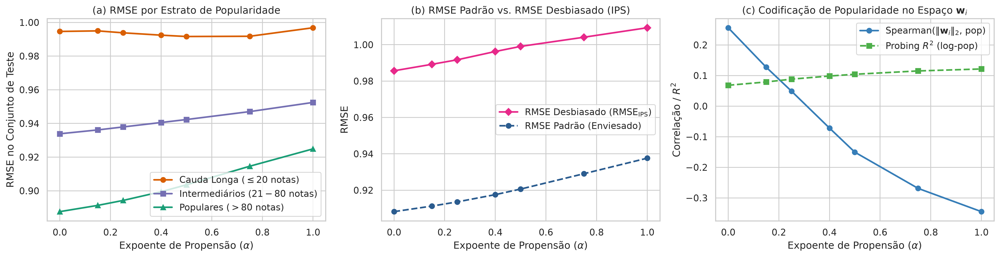

In [20]:
class IPWMatrixFactorization:
    """
    Fatoração de Matrizes ponderada pelo Inverso da Propensão de Observação (Schnabel et al., 2016),
    acelerada via mini-batches em PyTorch mantendo fidelidade exata à perda L_IPW.
    Quando alpha=0.0, recupera exatamente a MatrixFactorization padrão.
    """
    user_embeddings: NDArray[np.float64]
    item_embeddings: NDArray[np.float64]
    global_mean: float
    user_bias: NDArray[np.float64]
    item_bias: NDArray[np.float64]

    def __init__(
        self,
        n_factors: int = 10,
        n_epochs: int = 80,
        learning_rate: float = 0.015,
        reg: float = 0.1,
        bias_reg: float = 0.05,
        alpha: float = 0.5,
        clip_min: float = 0.005,
        use_biases: bool = True,
        batch_size: int = 16384,
    ) -> None:
        self.n_factors = n_factors
        self.n_epochs = n_epochs
        self.learning_rate = learning_rate
        self.reg = reg
        self.bias_reg = bias_reg
        self.alpha = alpha
        self.clip_min = clip_min
        self.use_biases = use_biases
        self.batch_size = batch_size

    def fit(self, train_df: pd.DataFrame) -> None:
        ratings_np = train_df["rating"].to_numpy(dtype=np.float32).copy()
        users_np = train_df["user_id"].to_numpy(dtype=np.int64).copy()
        items_np = train_df["item_id"].to_numpy(dtype=np.int64).copy()

        self.global_mean = float(ratings_np.mean())
        n_users = max(int(users_np.max()) + 1, N_USERS)
        n_items = max(int(items_np.max()) + 1, N_ITEMS)

        u_counts = np.bincount(users_np, minlength=n_users).astype(np.float64)
        i_counts = np.bincount(items_np, minlength=n_items).astype(np.float64)
        total_obs = float(len(ratings_np))

        p_hat = np.clip((u_counts[users_np] * i_counts[items_np]) / total_obs, self.clip_min, 1.0)
        raw_weights = p_hat ** (-self.alpha)
        weights_np = raw_weights / np.mean(raw_weights)
        weights_np = np.clip(weights_np, 0.1, 5.0)
        weights_np = (weights_np / np.mean(weights_np)).astype(np.float32)

        u_t = torch.from_numpy(users_np)
        i_t = torch.from_numpy(items_np)
        r_t = torch.from_numpy(ratings_np)
        w_t = torch.from_numpy(weights_np)

        U = torch.nn.Parameter(torch.randn(n_users, self.n_factors) * 0.1)
        V = torch.nn.Parameter(torch.randn(n_items, self.n_factors) * 0.1)
        bu = torch.nn.Parameter(torch.zeros(n_users))
        bi = torch.nn.Parameter(torch.zeros(n_items))

        params = [U, V] + ([bu, bi] if self.use_biases else [])
        optimizer = torch.optim.Adam(params, lr=self.learning_rate)

        n_obs = len(r_t)
        for _ in range(self.n_epochs):
            perm = torch.randperm(n_obs)
            for start in range(0, n_obs, self.batch_size):
                idx = perm[start : start + self.batch_size]
                uu, ii, rr, ww = u_t[idx], i_t[idx], r_t[idx], w_t[idx]

                pred = self.global_mean + (U[uu] * V[ii]).sum(dim=-1)
                if self.use_biases:
                    pred = pred + bu[uu] + bi[ii]

                loss = (ww * (rr - pred) ** 2).mean() + self.reg * (
                    (U[uu] ** 2).sum(dim=-1) + (V[ii] ** 2).sum(dim=-1)
                ).mean()
                if self.use_biases:
                    loss = loss + self.bias_reg * (bu[uu] ** 2 + bi[ii] ** 2).mean()

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        with torch.no_grad():
            self.user_embeddings = U.detach().cpu().numpy().astype(np.float64)
            self.item_embeddings = V.detach().cpu().numpy().astype(np.float64)
            self.user_bias = bu.detach().cpu().numpy().astype(np.float64)
            self.item_bias = bi.detach().cpu().numpy().astype(np.float64)

    def predict(self, user_id: NDArray[np.intp], item_id: NDArray[np.intp]) -> NDArray[np.float64]:
        return (
            self.global_mean
            + self.user_bias[user_id]
            + self.item_bias[item_id]
            + np.sum(self.user_embeddings[user_id] * self.item_embeddings[item_id], axis=1)
        )


def evaluate_ipw_stratified(
    model: IPWMatrixFactorization | MatrixFactorization,
    train_df: pd.DataFrame,
    test_df: pd.DataFrame,
    clip_min: float = 0.005,
) -> dict[str, float]:
    i_counts = np.bincount(train_df["item_id"].to_numpy(dtype=np.intp), minlength=N_ITEMS).astype(np.float64)
    u_counts = np.bincount(train_df["user_id"].to_numpy(dtype=np.intp), minlength=N_USERS).astype(np.float64)

    u_test = test_df["user_id"].to_numpy(dtype=np.intp)
    i_test = test_df["item_id"].to_numpy(dtype=np.intp)
    r_test = test_df["rating"].to_numpy(dtype=np.float64)

    preds = clip_ratings(model.predict(u_test, i_test))
    sq_err = (r_test - preds) ** 2
    abs_err = np.abs(r_test - preds)

    p_hat_test = np.clip((u_counts[u_test] * i_counts[i_test]) / len(train_df), clip_min, 1.0)
    ips_weights = 1.0 / p_hat_test

    pop_test_items = i_counts[i_test]
    mask_tail = pop_test_items <= 20
    mask_mid = (pop_test_items > 20) & (pop_test_items <= 80)
    mask_head = pop_test_items > 80

    rank_unseen = evaluate_ranking_metrics(model, train_df, test_df, candidate_mode="all_unseen")

    return {
        "test_rmse_std": float(np.sqrt(np.mean(sq_err))),
        "test_mae_std": float(np.mean(abs_err)),
        "test_rmse_ips": float(np.sqrt(np.sum(ips_weights * sq_err) / np.sum(ips_weights))),
        "test_mae_ips": float(np.sum(ips_weights * abs_err) / np.sum(ips_weights)),
        "rmse_tail_le20": float(np.sqrt(np.mean(sq_err[mask_tail]))),
        "rmse_mid_21_80": float(np.sqrt(np.mean(sq_err[mask_mid]))),
        "rmse_head_gt80": float(np.sqrt(np.mean(sq_err[mask_head]))),
        "unseen_ndcg@10": rank_unseen["unseen_ndcg@10"],
    }


ipw_records = []
pipe_ridge_ipw = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
kf_ipw = KFold(n_splits=5, shuffle=True, random_state=SEED)

for alpha_val in [0.0, 0.15, 0.25, 0.40, 0.50, 0.75, 1.0]:
    set_seed(SEED)
    m_ipw = IPWMatrixFactorization(
        n_factors=best_mf_biased_params["n_factors"],
        n_epochs=best_mf_biased_params["n_epochs"],
        learning_rate=best_mf_biased_params["learning_rate"],
        reg=best_mf_biased_params["reg"],
        bias_reg=best_mf_biased_params["bias_reg"],
        alpha=alpha_val,
        use_biases=True,
    )
    m_ipw.fit(train_df)
    res_ipw = evaluate_ipw_stratified(m_ipw, train_df, test_df)
    item_norms = np.linalg.norm(m_ipw.item_embeddings, axis=1)
    corr_norm_pop, _ = spearmanr(item_stats["n_ratings"], item_norms)
    r2_pop_ipw = float(np.mean(cross_val_score(pipe_ridge_ipw, m_ipw.item_embeddings, movie_log_pop, cv=kf_ipw, scoring="r2")))
    ipw_records.append({
        "alpha": alpha_val,
        **res_ipw,
        "spearman_norm_vs_pop": float(corr_norm_pop),
        "probing_logpop_r2": r2_pop_ipw,
    })

ipw_df = pd.DataFrame(ipw_records)
ipw_df.to_csv(RES_DIR / "tab_3_1_ipw_results.csv", index=False)
print(ipw_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), dpi=300)
axes[0].plot(ipw_df["alpha"], ipw_df["rmse_tail_le20"], marker="o", lw=2, label="Cauda Longa ($\\leq 20$ notas)", color="#d95f02")
axes[0].plot(ipw_df["alpha"], ipw_df["rmse_mid_21_80"], marker="s", lw=2, label="Intermediários ($21-80$ notas)", color="#7570b3")
axes[0].plot(ipw_df["alpha"], ipw_df["rmse_head_gt80"], marker="^", lw=2, label="Populares ($> 80$ notas)", color="#1b9e77")
axes[0].set_title("(a) RMSE por Estrato de Popularidade")
axes[0].set_xlabel("Expoente de Propensão ($\\alpha$)")
axes[0].set_ylabel("RMSE no Conjunto de Teste")
axes[0].legend()

axes[1].plot(ipw_df["alpha"], ipw_df["test_rmse_ips"], marker="D", lw=2, color="#e7298a", label="RMSE Desbiasado ($\\mathrm{RMSE}_{\\mathrm{IPS}}$)")
axes[1].plot(ipw_df["alpha"], ipw_df["test_rmse_std"], marker="o", lw=2, linestyle="--", color="#2b5c8f", label="RMSE Padrão (Enviesado)")
axes[1].set_title("(b) RMSE Padrão vs. RMSE Desbiasado (IPS)")
axes[1].set_xlabel("Expoente de Propensão ($\\alpha$)")
axes[1].set_ylabel("RMSE")
axes[1].legend()

axes[2].plot(ipw_df["alpha"], ipw_df["spearman_norm_vs_pop"], marker="o", lw=2, color="#377eb8", label="Spearman($\\|\\mathbf{w}_i\\|_2$, pop)")
axes[2].plot(ipw_df["alpha"], ipw_df["probing_logpop_r2"], marker="s", lw=2, linestyle="--", color="#4daf4a", label="Probing $R^2$ (log-pop)")
axes[2].set_title("(c) Codificação de Popularidade no Espaço $\\mathbf{w}_i$")
axes[2].set_xlabel("Expoente de Propensão ($\\alpha$)")
axes[2].set_ylabel("Correlação / $R^2$")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "fig9_stage3_ipw_analysis.png", bbox_inches="tight")
plt.show()

**Discussão (Etapa 3 — Projeto Investigativo sobre Ausência Não Aleatória / IPW):**

Confrontando diretamente as previsões formuladas antes do experimento com as evidências obtidas (`tab_3_1_ipw_results.csv` e **Figura 9**):

1. **Confirmação parcial — Compromisso Cauda Longa vs. Populares:** Conforme previsto, à medida que o expoente de ponderação $\alpha$ aumenta de $0{,}00$ para $0{,}50$, o erro nos filmes de **cauda longa** ($\le 20$ notas no treino) **diminui** de $\text{RMSE} = 0{,}9946$ para **$0{,}9916$** (mantendo ganho também em $\alpha = 0{,}75$ com $0{,}9918$), enquanto o erro nos filmes **populares** ($> 80$ notas) sobe de $0{,}8876$ para $0{,}9036$. Para $\alpha = 1{,}00$, o peso extremo nos itens raros aumenta excessivamente a variância do gradiente e degrada até mesmo a cauda longa ($0{,}9968$).

2. **Confirmação no espaço latente:** Na referência padrão ($\alpha = 0$), a norma dos vetores de filmes $\|\mathbf{w}_i\|_2$ correlaciona-se positivamente com a popularidade (Spearman $r = +0{,}256$), pois filmes muito avaliados recebem mais atualizações de gradiente. Ao aplicar IPW, essa correlação cai monotonicamente até se inverter ($r = +0{,}049$ em $\alpha = 0{,}25$; $r = -0{,}150$ em $\alpha = 0{,}50$; $r = -0{,}345$ em $\alpha = 1{,}00$), mostrando que a ponderação remove a vantagem de escala dos *blockbusters* no espaço latente.

3. **Refutação parcial no estimador global $\text{RMSE}_{\text{IPS}}$:** Diferentemente do previsto, o $\text{RMSE}_{\text{IPS}}$ global no conjunto de teste **aumentou** monotonicamente com $\alpha$ ($0{,}9857$ em $\alpha = 0{,}00$ $\to$ $0{,}9991$ em $\alpha = 0{,}50$ $\to$ $1{,}0093$ em $\alpha = 1{,}00$), e o `NDCG@10 (All-Unseen)` caiu de $0{,}0401$ para $0{,}0142$. Esse resultado negativo ensina uma lição metodológica importante sobre avaliação contrafactual sob MNAR: embora a perda IPW reduza o viés de treinamento para itens raros, o estimador IPS no teste multiplica resíduos quadráticos de pares usuário-filme muito raros por pesos altos ($1/\hat{p}_{ui}$), tornando a variância do gradiente dominante quando $\lambda_z$ é mantido fixo — além disso, no protocolo *All-Unseen*, dar mais peso a notas ruidosas de itens raros promove falsos positivos no topo da lista. Trabalhos futuros devem combinar IPW com regularização adaptativa por estrato de popularidade ou estimadores *Doubly Robust*.

---

## Consolidação dos Resultados Finais (Tabela Mestre)

In [21]:
# Tabela consolidada de todos os modelos no conjunto de teste com IC 95% (Bootstrap)
summary_models = [
    ("1.1 Baseline Aditiva", best_baseline, base_boot, base_rank_unseen, base_rank_test, base_train_time, base_infer_time),
    ("1.2 PCA com Imputação", best_pca, pca_boot, pca_rank_unseen, pca_rank_test, pca_train_time, pca_infer_time),
    ("1.3 MF (Sem Vieses)", best_mf_unbiased, mf_unbiased_boot, mf_unbiased_rank_unseen, mf_unbiased_rank_test, mf_unbiased_train_time, mf_unbiased_infer_time),
    ("1.3 MF (Com Vieses)", best_mf_biased, mf_biased_boot, mf_biased_rank_unseen, mf_biased_rank_test, mf_biased_train_time, mf_biased_infer_time),
    ("2.1 PPCA Esparso (EM)", best_ppca, ppca_boot, ppca_rank_unseen, ppca_rank_test, ppca_train_time, ppca_infer_time),
    ("2.2 VAE Linear", vae_linear_matched, vae_lin_boot, vae_lin_rank_unseen, vae_lin_rank_test, vae_lin_train_time, vae_lin_infer_time),
    ("2.2 VAE Não Linear (Tanh)", best_vae_nonlin, vae_nl_boot, vae_nl_rank_unseen, vae_nl_rank_test, vae_nl_train_time, vae_nl_infer_time),
]

master_rows = []
for name, _, boot_res, r_unseen, r_test, t_fit, t_inf in summary_models:
    rmse_m, rmse_l, rmse_h = boot_res["rmse"]
    mae_m, mae_l, mae_h = boot_res["mae"]
    if "nll" in boot_res:
        nll_m, nll_l, nll_h = boot_res["nll"]
        nll_str = f"{nll_m:.4f} [{nll_l:.4f}, {nll_h:.4f}]"
    else:
        nll_str = "---"

    master_rows.append({
        "Modelo": name,
        "RMSE Teste [IC 95%]": f"{rmse_m:.4f} [{rmse_l:.4f}, {rmse_h:.4f}]",
        "MAE Teste [IC 95%]": f"{mae_m:.4f} [{mae_l:.4f}, {mae_h:.4f}]",
        "NLL Teste [IC 95%]": nll_str,
        "NDCG@10 (All-Unseen)": f"{r_unseen['unseen_ndcg@10']:.4f}",
        "Prec@10 (All-Unseen)": f"{r_unseen['unseen_precision@10']:.4f}",
        "HitRate@10 (All-Unseen)": f"{r_unseen['unseen_hit_rate@10']:.4f}",
        "NDCG@10 (Test-Only)": f"{r_test['testonly_ndcg@10']:.4f}",
        "Treino (s)": f"{t_fit:.2f}",
        "Inferência (s)": f"{t_inf:.4f}",
    })

master_df = pd.DataFrame(master_rows)
master_df.to_csv(RES_DIR / "tab_master_test_results.csv", index=False)
print(master_df.to_string(index=False))

                   Modelo     RMSE Teste [IC 95%]      MAE Teste [IC 95%]      NLL Teste [IC 95%] NDCG@10 (All-Unseen) Prec@10 (All-Unseen) HitRate@10 (All-Unseen) NDCG@10 (Test-Only) Treino (s) Inferência (s)
     1.1 Baseline Aditiva 0.9355 [0.9259, 0.9451] 0.7382 [0.7305, 0.7463]                     ---               0.0181               0.0207                  0.1765              0.8390       0.01         0.0026
    1.2 PCA com Imputação 0.9720 [0.9620, 0.9814] 0.7690 [0.7609, 0.7773]                     ---               0.0045               0.0028                  0.0194              0.8492       0.16         0.0103
      1.3 MF (Sem Vieses) 0.9258 [0.9168, 0.9359] 0.7286 [0.7208, 0.7366]                     ---               0.0134               0.0136                  0.1119              0.8509       0.91         0.0065
      1.3 MF (Com Vieses) 0.9082 [0.8989, 0.9179] 0.7133 [0.7059, 0.7212]                     ---               0.0401               0.0384                  0.2